# Do ABCD factors measured with prompt lepton jets carry over to displaced ones?

The background estimate of the search is an ABCD in the plane of $|\Delta\phi|$ between the two
lepton jets (LJs) against the leading muon LJ's isolation, with the other LJ's isolation below 0.5
and the LJ-pair mass above 150 GeV required at the event level. The search region is the corner
of that plane with both LJs displaced: leading muon LJ isolation < 0.25 and $|\Delta\phi| \ge 2.4$.
Its closure, $\kappa = A\,D/(B\,C)$, can only be checked where the isolated, back-to-back corner A
is open, which so far has meant the plane with the displacement requirement inverted on both LJs
(the validation plane). There the 2018 data close to within 5–25% depending on the boundaries,
the plane with both LJs displaced has too few events in its open regions to test anything, and
the simulation has about one effective event in the search region. The question of this notebook
is whether the quantities the method needs can be *measured* with prompt LJs and *used* with
displaced ones, which would move the statistical weight of the estimate to where the data are.

The test is done per axis. The ABCD prediction $A = B\,C/D$ can be read as

$$A = C \times \frac{B}{D} \qquad\text{or}\qquad A = B \times \frac{C}{D},$$

where $B/D$ is the pass/fail ratio of one axis among events that fail the other axis, and $C/D$ the
same with the roles exchanged. A ratio may be taken from another plane only if it does not depend
on the displacement requirement that differs between the two planes. Two things are then kept
apart throughout:

- $B/D$ and $C/D$ are the ratios *among failures* of the other axis. They are open everywhere,
  including the search plane, and are what the fail slices can test.
- The search region itself needs the ratio *among passes* of the other axis, $A/C$ or $A/B$.
  That is open only where A is, so its transfer can be tested in the one-LJ-displaced planes
  and at low mass, never in the search plane itself. Writing the prediction as
  $C \times (B/D)_{\text{other plane}}$ does not avoid this: it equals the in-plane
  $B\,C/D$ times the ratio of the two $B/D$ values and assumes $\kappa = 1$ in the search plane
  just as the in-plane estimate does.

Two planes are examined. The **analysis plane** ($|\Delta\phi|$ × leading-muon-LJ isolation,
section 1) is the one the estimate uses. The **companion plane** of the two LJ isolations
(section 2) separates the two LJs' isolation responses, which is where the physical cause of a
non-transferring factor can be seen; it is also the plane in which the validation-plane closure
was first shown.

**Inputs.** Dongyub Lee's inclusive six-dimensional histograms (campaign
`ABCD_6D_inclusive_eHEM_skimv1`, 2018 data and simulation, read-only copies made by
`fetch_6d.sh`). Each event enters once with the leading muon LJ's isolation and maximum pixel
hits, the leading egamma LJ's isolation and minimum lost hits (2μ2e) or the subleading muon
LJ's isolation and pixel hits (4μ), $|\Delta\phi|$ between the two LJs and their pair mass.
Cosmic veto, DSA cross-cleaning, muon veto and the electron HEM veto are applied in the fill;
no isolation, displacement, $\Delta\phi$ or mass requirement is. Every region below is a
projection of that cube (`abcd6d_io.py`, `transfer_lib.py`).

**Definitions.**

| symbol | meaning |
|---|---|
| object 0, object 1 | 2μ2e: leading muon LJ, leading egamma LJ. 4μ: leading, subleading muon LJ |
| displaced | muon LJ: max pixel hits ≤ 2; egamma LJ: min lost hits ≥ 1 (photon-only LJs carry the lost-hits sentinel 999 and count as displaced). Prompt = the complement |
| plane PP, DP, PD, DD | displacement state of (object 0, object 1): PP both prompt (validation plane), DD both displaced (search plane), DP and PD one each |
| mass window | M ≥ 150 GeV (the analysis requirement) or M < 150 GeV. Nothing measured below 150 GeV is projected above it: the mass requirement changes the kinematics, so the low-mass rows only ask whether a plane factorises at all |
| isolation pass / fail | isolation < 0.25 / isolation ≥ 0.5. The 0.25–0.5 strip belongs to no region: it keeps the fail slices away from the search region and from the hidden box |
| analysis plane | object 0 isolation against $\lvert\Delta\phi\rvert$, object 1 isolation < 0.5 at the event level. $\Delta\phi$ pass: ≥ 2.4, fail: < 2.0 (the 2.0–2.4 strip belongs to no region). A = isolation pass & $\Delta\phi$ pass, B = fail & pass, C = pass & fail, D = fail & fail |
| companion plane | object 0 isolation against object 1 isolation, with $\lvert\Delta\phi\rvert \ge 2$: A = pass/pass, B = fail/pass, C = pass/fail, D = fail/fail (first letter = object 0) |
| r1 = B/D, A/C | pass/fail ratio of the second axis among failures / passes of the first |
| r0 = C/D, A/B | pass/fail ratio of the first axis among failures / passes of the second |
| κ | A·D/(B·C), the in-plane non-closure; the ABCD estimate assumes κ = 1 |

**Blinding.** The search region is A of the analysis plane in the DD plane at M ≥ 150 GeV. The
data cubes are loaded with that region plus a margin on both of its axes set to NaN: DD plane,
M ≥ 150 GeV, object 0 isolation < 0.5 (the search region ends at 0.25), $|\Delta\phi| \ge 2$ (the
search region starts at 2.4), object 1 isolation < 0.5 (the search region's own edge). Any
projection touching a hidden cell is NaN and prints as "blind", so the hidden count can be neither
printed nor recovered by subtraction. In 4μ the isolated corners of the two one-LJ-displaced
planes are hidden as well: they hold up to half of the signal's search-region yield at the stored
normalisation (section 4), comparable to the background the prompt-plane factors predict there
(section 1c). Everything else is open. What is open and used, with the signal it holds at the stored normalisation, is listed
in section 4; the regions closest to the search region are its fail slices in the DD plane
(B, C and D of both planes at M ≥ 150 GeV), the isolated $|\Delta\phi| < 2$ corner of the DD plane
(C of the analysis plane), the isolated DD corner at M < 150 GeV, and in 2μ2e the isolated corners
of the DP and PD planes. Looking at these is a change from the practice so far, which has used
data only in the validation plane; it should be agreed with the group before the numbers are
circulated. Simulation is never blinded.

**Uncertainties.** Data ratios of disjoint counts carry the 68.27% Clopper–Pearson interval of
the corresponding fraction mapped to the ratio; a prediction from a count of zero carries the 68%
Poisson upper limit (1.84 × factor) as its upward error; weighted simulation uses sumw²
propagation. Shape comparisons use the two-sample χ² with pooled expected contents, which keeps
its calibration down to a few tens of events in the smaller sample; with a handful of events there
(the 4μ rows with one event) the p-value is indicative only.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE = tl.local_dir()
print("inputs:", BASE)
for kind in ("data", "bkg", "signal"):
    print(f"  {kind}: {len(tl.sample_paths(BASE, kind))} files")

data = tl.summed_cubes(BASE, "data")       # always blinded; nothing of the hidden box is printed
print("hidden box:", io.blind_signature())
for t, c in data.items():
    print(f"{t}: {int(np.isnan(c.sumw).sum())} hidden cells")

inputs: /uscms_data/d3/murtazas/abcd6d_local
  data: 68 files
  bkg: 18 files
  signal: 180 files


hidden box: iso<0.5 mass>=150 dphi>=2 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: 320760 hidden cells
4mu: 769824 hidden cells


## 0. Positive control: the validation-plane closures of the status report

Before anything new, the projections are checked against the numbers Dongyub showed on
2026-10-08 for the validation plane (PP, M ≥ 150 GeV), with his region conventions (no buffers:
fail = not pass). Companion plane at $|\Delta\phi| \ge 2$: 2μ2e κ = 0.928 ± 0.059 at the 0.25/0.25
working point and 1.05 ± 0.056 at 0.5/0.5; 4μ κ = 5.6 ± 0.7 and 2.6 ± 0.24. Analysis plane with the
other LJ's isolation < 0.5, object 0 isolation boundary 0.25 and $|\Delta\phi|$ boundary 2.0:
2μ2e κ = 0.76 ± 0.10, 4μ κ = 1.38 ± 0.37. The projections here include the isolation underflow bin
(isolation < 0, a handful of events) that his region definitions leave out, and differences of one
or two events in A remain; they change no conclusion and were not traced further.

In [2]:
rows = []
for t in tl.TOPOLOGIES:
    for wp in (0.25, 0.5):
        reg = tl.regions(data[t], "PP", "M>=150", wp=wp, fail=wp)
        f = tl.factors(reg)
        rows.append({"topology": t, "plane": "companion (iso x iso)", "boundaries": f"iso {wp}/{wp}",
                     **{r: tl.fmt_count(reg[r]) for r in "ABCD"}, "B C / D": tl.fmt(f["pred"], 1), "kappa": tl.fmt(f["kappa"])})
    reg = tl.dphi_regions(data[t], "PP", "M>=150", wp=0.25, fail=0.25, dphi_pass=2.0, dphi_fail=2.0, other_iso=0.5)
    f = tl.factors(reg)
    rows.append({"topology": t, "plane": "analysis (dphi x iso0)", "boundaries": "iso0 0.25, dphi 2.0, iso1 < 0.5",
                 **{r: tl.fmt_count(reg[r]) for r in "ABCD"}, "B C / D": tl.fmt(f["pred"], 1), "kappa": tl.fmt(f["kappa"])})
pd.DataFrame(rows)

,topology,plane,boundaries,A,B,C,D,B C / D,kappa
0,2mu2e,companion (iso x iso),iso 0.25/0.25,481,1039,1453,2914,518.1 ± 23.1,0.928 ± 0.059
1,2mu2e,companion (iso x iso),iso 0.5/0.5,1478,1148,1797,1464,1409.1 ± 64.7,1.049 ± 0.055
2,2mu2e,analysis (dphi x iso0),"iso0 0.25, dphi 2.0, iso1 < 0.5",878,1748,121,184,1149.5 ± 137.3,0.764 ± 0.095
3,4mu,companion (iso x iso),iso 0.25/0.25,190,131,426,1673,33.4 ± 3.4,5.696 ± 0.717
4,4mu,companion (iso x iso),iso 0.5/0.5,462,229,757,972,178.3 ± 14.6,2.590 ± 0.244
5,4mu,analysis (dphi x iso0),"iso0 0.25, dphi 2.0, iso1 < 0.5",299,392,23,42,214.7 ± 56.7,1.393 ± 0.377


## 1. The analysis plane: $|\Delta\phi|$ × leading-muon-LJ isolation

### 1a. The four planes side by side

Region counts, the four pass/fail ratios and the in-plane κ in each plane, with the buffered
regions used from here on. A of the DD plane at M ≥ 150 GeV is the search region and is blind,
so its κ, A/C and A/B are not available; in 4μ the same holds for the DP and PD planes. The
M < 150 GeV rows ask whether the plane factorises at low mass, where the DD corner is open.

How to read it: if displacement did not matter, every column would be constant down the four
planes. κ ≠ 1 in a plane means the two axes are correlated there; a ratio changing between
planes means the corresponding axis responds to displacement.

In [3]:
for t in tl.TOPOLOGIES:
    print(t, "— planes:", "; ".join(f"{p}: {tl.plane_label(t, p)}" for p in tl.PLANES))
    display(tl.dphi_table(data[t]))

2mu2e — planes: PP: mu-LJ prompt, EGM-LJ prompt; DP: mu-LJ displaced, EGM-LJ prompt; PD: mu-LJ prompt, EGM-LJ displaced; DD: mu-LJ displaced, EGM-LJ displaced


,mass,plane,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,M>=150,PP,797,1021,121,130,7.854 -0.728 +0.805,6.587 -0.639 +0.711,0.931 -0.117 +0.134,0.781 ± 0.039,950.3 ± 123.7,0.839 ± 0.113
1,M>=150,DP,44,54,5,7,7.714 -2.869 +4.907,8.800 -3.746 +7.242,0.714 -0.380 +0.784,0.815 -0.163 +0.204,38.6 ± 23.2,1.141 ± 0.707
2,M>=150,PD,1343,886,196,163,5.436 -0.461 +0.506,6.852 -0.522 +0.567,1.202 -0.127 +0.142,1.516 ± 0.069,1065.4 ± 118.5,1.261 ± 0.144
3,M>=150,DD,blind,50,11,14,3.571 -1.036 +1.501,n/a,0.786 -0.301 +0.483,n/a,39.3 ± 16.8,n/a
4,M<150,PP,383,418,346,732,0.571 -0.035 +0.037,1.107 -0.082 +0.088,0.473 -0.031 +0.033,0.916 -0.065 +0.070,197.6 ± 16.1,1.938 ± 0.187
5,M<150,DP,14,17,18,37,0.459 -0.132 +0.181,0.778 -0.267 +0.402,0.486 -0.137 +0.187,0.824 -0.285 +0.434,8.3 ± 3.1,1.693 ± 0.781
6,M<150,PD,878,382,636,618,0.618 -0.040 +0.043,1.381 -0.072 +0.076,1.029 -0.058 +0.062,2.298 -0.141 +0.150,393.1 ± 30.0,2.233 ± 0.186
7,M<150,DD,41,26,47,38,0.684 -0.171 +0.226,0.872 -0.184 +0.232,1.237 -0.265 +0.338,1.577 -0.386 +0.515,32.2 ± 9.4,1.275 ± 0.424


4mu — planes: PP: leading mu-LJ prompt, subleading mu-LJ prompt; DP: leading mu-LJ displaced, subleading mu-LJ prompt; PD: leading mu-LJ prompt, subleading mu-LJ displaced; DD: leading mu-LJ displaced, subleading mu-LJ displaced


,mass,plane,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,M>=150,PP,264,198,23,28,7.071 -1.397 +1.770,11.478 -2.432 +3.152,0.821 -0.225 +0.309,1.333 -0.125 +0.138,162.6 ± 47.2,1.623 ± 0.482
1,M>=150,DP,blind,24,4,1,24.000 -17.067 +120.220,n/a,4.000 -3.093 +24.447,n/a,96.0 ± 109.1,n/a
2,M>=150,PD,blind,14,7,8,1.750 -0.722 +1.267,n/a,0.875 -0.418 +0.791,n/a,12.2 ± 7.1,n/a
3,M>=150,DD,blind,1,0,0,n/a,n/a,n/a,n/a,n/a,n/a
4,M<150,PP,332,399,126,216,1.847 -0.156 +0.170,2.635 -0.274 +0.307,0.583 -0.065 +0.073,0.832 -0.062 +0.067,232.8 ± 28.6,1.426 ± 0.192
5,M<150,DP,30,22,27,18,1.222 -0.375 +0.544,1.111 -0.288 +0.389,1.500 -0.441 +0.631,1.364 -0.372 +0.514,33.0 ± 12.3,0.909 ± 0.376
6,M<150,PD,15,29,23,17,1.706 -0.502 +0.722,0.652 -0.210 +0.305,1.353 -0.417 +0.608,0.517 -0.160 +0.227,39.2 ± 14.5,0.382 ± 0.172
7,M<150,DD,2,0,3,1,0.000 -0.000 +5.303,0.667 -0.495 +1.705,3.000 -2.383 +19.659,n/a,n/a,n/a


### 1b. Each ratio across each change of displacement

$|\Delta\phi|$ is an event quantity, so there is no a-priori "legitimate" pair here: each of the
four ratios is compared across each single change of displacement (object 0 prompt → displaced
with object 1 held, and the reverse). The last column is the displaced-over-prompt ratio; 1
within its uncertainty is what a transferable quantity looks like. The rows that end in the DD
plane are the ones a search-region prediction would rely on: for s = B/D and t = C/D both ends
are open; for A/C and A/B the DD end is the search region and the row is blind, so those
quantities can only be tested across the changes that end in DP or PD.

In [4]:
for t in tl.TOPOLOGIES:
    for mass in ("M>=150", "M<150"):
        print(f"{t}, {mass}")
        display(tl.dphi_transfer_table(data[t], mass))

2mu2e, M>=150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,s = B/D: |dphi| pass/fail ratio among iso0 failures,mu-LJ: PP -> DP,"B=1021, D=130",7.854 -0.728 +0.805,"B=54, D=7",7.714 -2.869 +4.907,0.982 -0.379 +0.631
1,s = B/D: |dphi| pass/fail ratio among iso0 failures,mu-LJ: PD -> DD,"B=886, D=163",5.436 -0.461 +0.506,"B=50, D=14",3.571 -1.036 +1.501,0.657 -0.200 +0.282
2,s = B/D: |dphi| pass/fail ratio among iso0 failures,EGM-LJ: PP -> PD,"B=1021, D=130",7.854 -0.728 +0.805,"B=886, D=163",5.436 -0.461 +0.506,0.692 ± 0.092
3,s = B/D: |dphi| pass/fail ratio among iso0 failures,EGM-LJ: DP -> DD,"B=54, D=7",7.714 -2.869 +4.907,"B=50, D=14",3.571 -1.036 +1.501,0.463 -0.324 +0.260
4,A/C: |dphi| pass/fail ratio among iso0 passes,mu-LJ: PP -> DP,"A=797, C=121",6.587 -0.639 +0.711,"A=44, C=5",8.800 -3.746 +7.242,1.336 -0.587 +1.107
5,A/C: |dphi| pass/fail ratio among iso0 passes,mu-LJ: PD -> DD,"A=1343, C=196",6.852 -0.522 +0.567,"A=blind, C=11",n/a,n/a
6,A/C: |dphi| pass/fail ratio among iso0 passes,EGM-LJ: PP -> PD,"A=797, C=121",6.587 -0.639 +0.711,"A=1343, C=196",6.852 -0.522 +0.567,1.040 ± 0.137
7,A/C: |dphi| pass/fail ratio among iso0 passes,EGM-LJ: DP -> DD,"A=44, C=5",8.800 -3.746 +7.242,"A=blind, C=11",n/a,n/a
8,t = C/D: iso0 pass/fail ratio among |dphi| failures,mu-LJ: PP -> DP,"C=121, D=130",0.931 -0.117 +0.134,"C=5, D=7",0.714 -0.380 +0.784,0.767 -0.423 +0.848
9,t = C/D: iso0 pass/fail ratio among |dphi| failures,mu-LJ: PD -> DD,"C=196, D=163",1.202 -0.127 +0.142,"C=11, D=14",0.786 -0.301 +0.483,0.653 -0.262 +0.408


2mu2e, M<150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,s = B/D: |dphi| pass/fail ratio among iso0 failures,mu-LJ: PP -> DP,"B=418, D=732",0.571 -0.035 +0.037,"B=17, D=37",0.459 -0.132 +0.181,0.805 -0.236 +0.321
1,s = B/D: |dphi| pass/fail ratio among iso0 failures,mu-LJ: PD -> DD,"B=382, D=618",0.618 -0.040 +0.043,"B=26, D=38",0.684 -0.171 +0.226,1.107 -0.287 +0.373
2,s = B/D: |dphi| pass/fail ratio among iso0 failures,EGM-LJ: PP -> PD,"B=418, D=732",0.571 -0.035 +0.037,"B=382, D=618",0.618 -0.040 +0.043,1.082 ± 0.100
3,s = B/D: |dphi| pass/fail ratio among iso0 failures,EGM-LJ: DP -> DD,"B=17, D=37",0.459 -0.132 +0.181,"B=26, D=38",0.684 -0.171 +0.226,1.489 -0.695 +0.651
4,A/C: |dphi| pass/fail ratio among iso0 passes,mu-LJ: PP -> DP,"A=383, C=346",1.107 -0.082 +0.088,"A=14, C=18",0.778 -0.267 +0.402,0.703 -0.247 +0.367
5,A/C: |dphi| pass/fail ratio among iso0 passes,mu-LJ: PD -> DD,"A=878, C=636",1.381 -0.072 +0.076,"A=41, C=47",0.872 -0.184 +0.232,0.632 -0.137 +0.171
6,A/C: |dphi| pass/fail ratio among iso0 passes,EGM-LJ: PP -> PD,"A=383, C=346",1.107 -0.082 +0.088,"A=878, C=636",1.381 -0.072 +0.076,1.247 ± 0.119
7,A/C: |dphi| pass/fail ratio among iso0 passes,EGM-LJ: DP -> DD,"A=14, C=18",0.778 -0.267 +0.402,"A=41, C=47",0.872 -0.184 +0.232,1.122 -0.626 +0.487
8,t = C/D: iso0 pass/fail ratio among |dphi| failures,mu-LJ: PP -> DP,"C=346, D=732",0.473 -0.031 +0.033,"C=18, D=37",0.486 -0.137 +0.187,1.029 -0.298 +0.402
9,t = C/D: iso0 pass/fail ratio among |dphi| failures,mu-LJ: PD -> DD,"C=636, D=618",1.029 -0.058 +0.062,"C=47, D=38",1.237 -0.265 +0.338,1.202 -0.267 +0.336


4mu, M>=150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,s = B/D: |dphi| pass/fail ratio among iso0 failures,leading mu-LJ: PP -> DP,"B=198, D=28",7.071 -1.397 +1.770,"B=24, D=1",24.000 -17.067 +120.220,3.394 -2.559 +17.014
1,s = B/D: |dphi| pass/fail ratio among iso0 failures,leading mu-LJ: PD -> DD,"B=14, D=8",1.750 -0.722 +1.267,"B=1, D=0",n/a,n/a
2,s = B/D: |dphi| pass/fail ratio among iso0 failures,subleading mu-LJ: PP -> PD,"B=198, D=28",7.071 -1.397 +1.770,"B=14, D=8",1.750 -0.722 +1.267,0.247 -0.119 +0.186
3,s = B/D: |dphi| pass/fail ratio among iso0 failures,subleading mu-LJ: DP -> DD,"B=24, D=1",24.000 -17.067 +120.220,"B=1, D=0",n/a,n/a
4,A/C: |dphi| pass/fail ratio among iso0 passes,leading mu-LJ: PP -> DP,"A=264, C=23",11.478 -2.432 +3.152,"A=blind, C=4",n/a,n/a
5,A/C: |dphi| pass/fail ratio among iso0 passes,leading mu-LJ: PD -> DD,"A=blind, C=7",n/a,"A=blind, C=0",n/a,n/a
6,A/C: |dphi| pass/fail ratio among iso0 passes,subleading mu-LJ: PP -> PD,"A=264, C=23",11.478 -2.432 +3.152,"A=blind, C=7",n/a,n/a
7,A/C: |dphi| pass/fail ratio among iso0 passes,subleading mu-LJ: DP -> DD,"A=blind, C=4",n/a,"A=blind, C=0",n/a,n/a
8,t = C/D: iso0 pass/fail ratio among |dphi| failures,leading mu-LJ: PP -> DP,"C=23, D=28",0.821 -0.225 +0.309,"C=4, D=1",4.000 -3.093 +24.447,4.870 -4.187 +29.791
9,t = C/D: iso0 pass/fail ratio among |dphi| failures,leading mu-LJ: PD -> DD,"C=7, D=8",0.875 -0.418 +0.791,"C=0, D=0",n/a,n/a


4mu, M<150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,s = B/D: |dphi| pass/fail ratio among iso0 failures,leading mu-LJ: PP -> DP,"B=399, D=216",1.847 -0.156 +0.170,"B=22, D=18",1.222 -0.375 +0.544,0.662 -0.212 +0.299
1,s = B/D: |dphi| pass/fail ratio among iso0 failures,leading mu-LJ: PD -> DD,"B=29, D=17",1.706 -0.502 +0.722,"B=0, D=1",0.000 -0.000 +5.303,0.000 -0.000 +3.109
2,s = B/D: |dphi| pass/fail ratio among iso0 failures,subleading mu-LJ: PP -> PD,"B=399, D=216",1.847 -0.156 +0.170,"B=29, D=17",1.706 -0.502 +0.722,0.923 -0.285 +0.399
3,s = B/D: |dphi| pass/fail ratio among iso0 failures,subleading mu-LJ: DP -> DD,"B=22, D=18",1.222 -0.375 +0.544,"B=0, D=1",0.000 -0.000 +5.303,0.000 -0.000 +4.339
4,A/C: |dphi| pass/fail ratio among iso0 passes,leading mu-LJ: PP -> DP,"A=332, C=126",2.635 -0.274 +0.307,"A=30, C=27",1.111 -0.288 +0.389,0.422 -0.120 +0.154
5,A/C: |dphi| pass/fail ratio among iso0 passes,leading mu-LJ: PD -> DD,"A=15, C=23",0.652 -0.210 +0.305,"A=2, C=3",0.667 -0.495 +1.705,1.022 -0.897 +2.634
6,A/C: |dphi| pass/fail ratio among iso0 passes,subleading mu-LJ: PP -> PD,"A=332, C=126",2.635 -0.274 +0.307,"A=15, C=23",0.652 -0.210 +0.305,0.248 -0.085 +0.118
7,A/C: |dphi| pass/fail ratio among iso0 passes,subleading mu-LJ: DP -> DD,"A=30, C=27",1.111 -0.288 +0.389,"A=2, C=3",0.667 -0.495 +1.705,0.600 -0.492 +1.542
8,t = C/D: iso0 pass/fail ratio among |dphi| failures,leading mu-LJ: PP -> DP,"C=126, D=216",0.583 -0.065 +0.073,"C=27, D=18",1.500 -0.441 +0.631,2.571 -0.822 +1.119
9,t = C/D: iso0 pass/fail ratio among |dphi| failures,leading mu-LJ: PD -> DD,"C=23, D=17",1.353 -0.417 +0.608,"C=3, D=1",3.000 -2.383 +19.659,2.217 -2.023 +14.546


The integrated ratios are single numbers; the same comparison as a shape. Left: the
$|\Delta\phi|$ distribution of events whose muon LJ fails isolation (≥ 0.5), per plane, normalised
to unit area, with the ratio to PP below; right: the same among events whose muon LJ passes
(< 0.25). The DD plane is hidden at $|\Delta\phi| \ge 2$ in the pass slice and is not drawn there.
The region above 2.4 is where s and A/C are set; bins with no event in the compared plane are not
drawn in the ratio panel. The table gives the pooled two-sample χ² between planes.

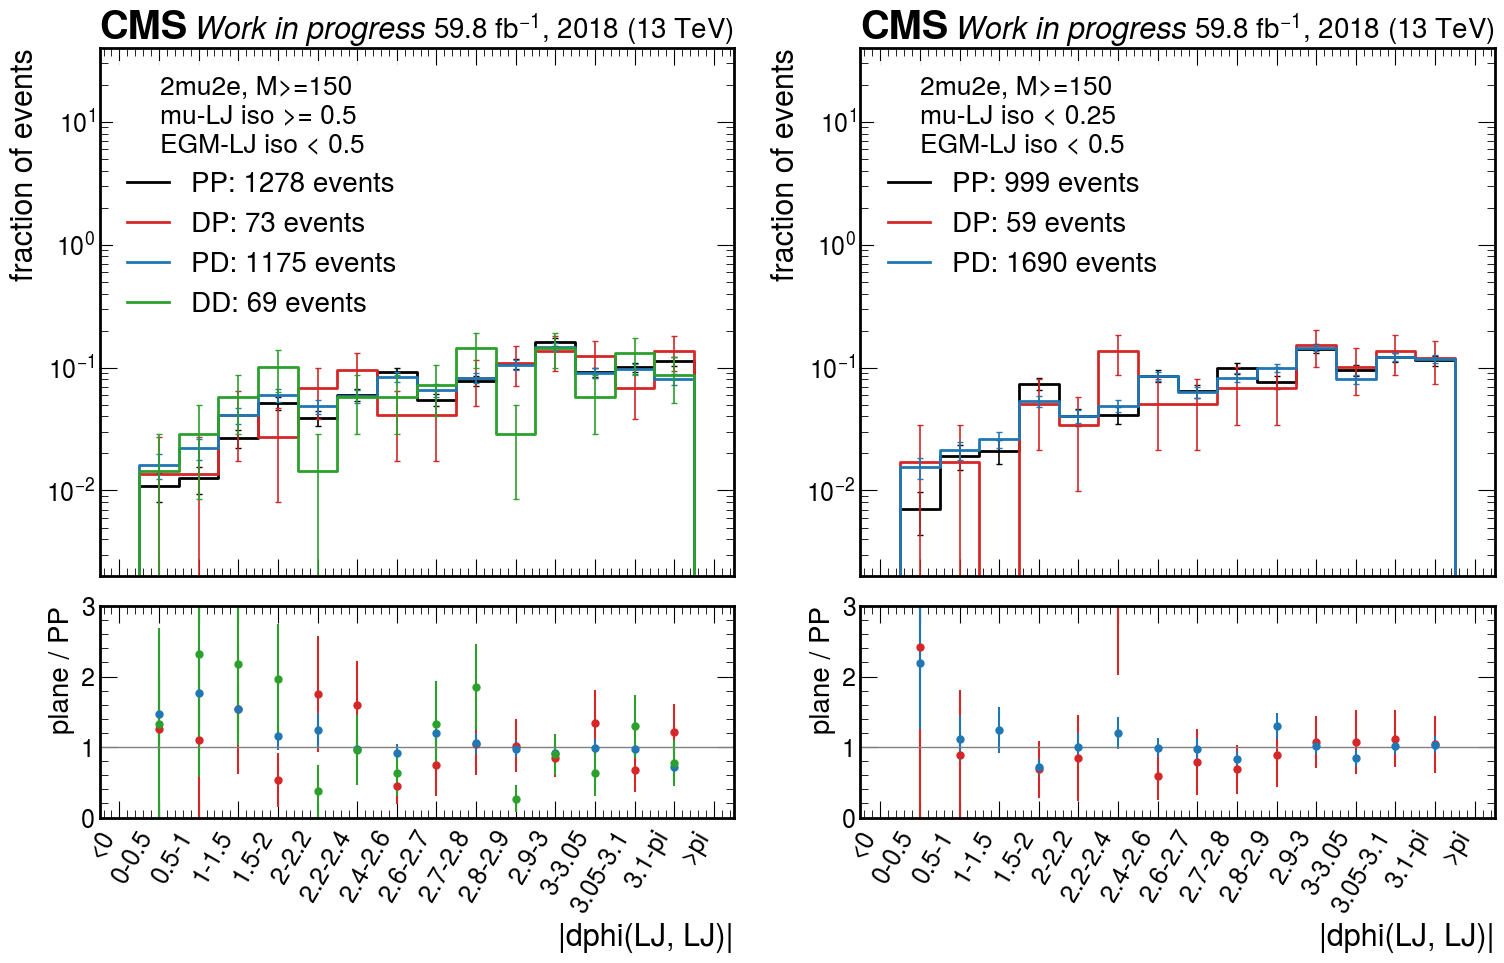

,shape,planes,events,chi2/ndf,p
0,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PP vs DP,1278 vs 73,8.6/13,0.802
1,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PP vs PD,1278 vs 1175,19.1/13,0.119
2,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PD vs DD,1175 vs 69,12.8/13,0.462
3,"|dphi| where iso0 >= 0.5, iso1 < 0.5",DP vs DD,73 vs 69,15.9/13,0.252
4,"|dphi| where iso0 < 0.25, iso1 < 0.5",PP vs DP,999 vs 59,15.0/13,0.310
5,"|dphi| where iso0 < 0.25, iso1 < 0.5",PP vs PD,999 vs 1690,16.9/13,0.204


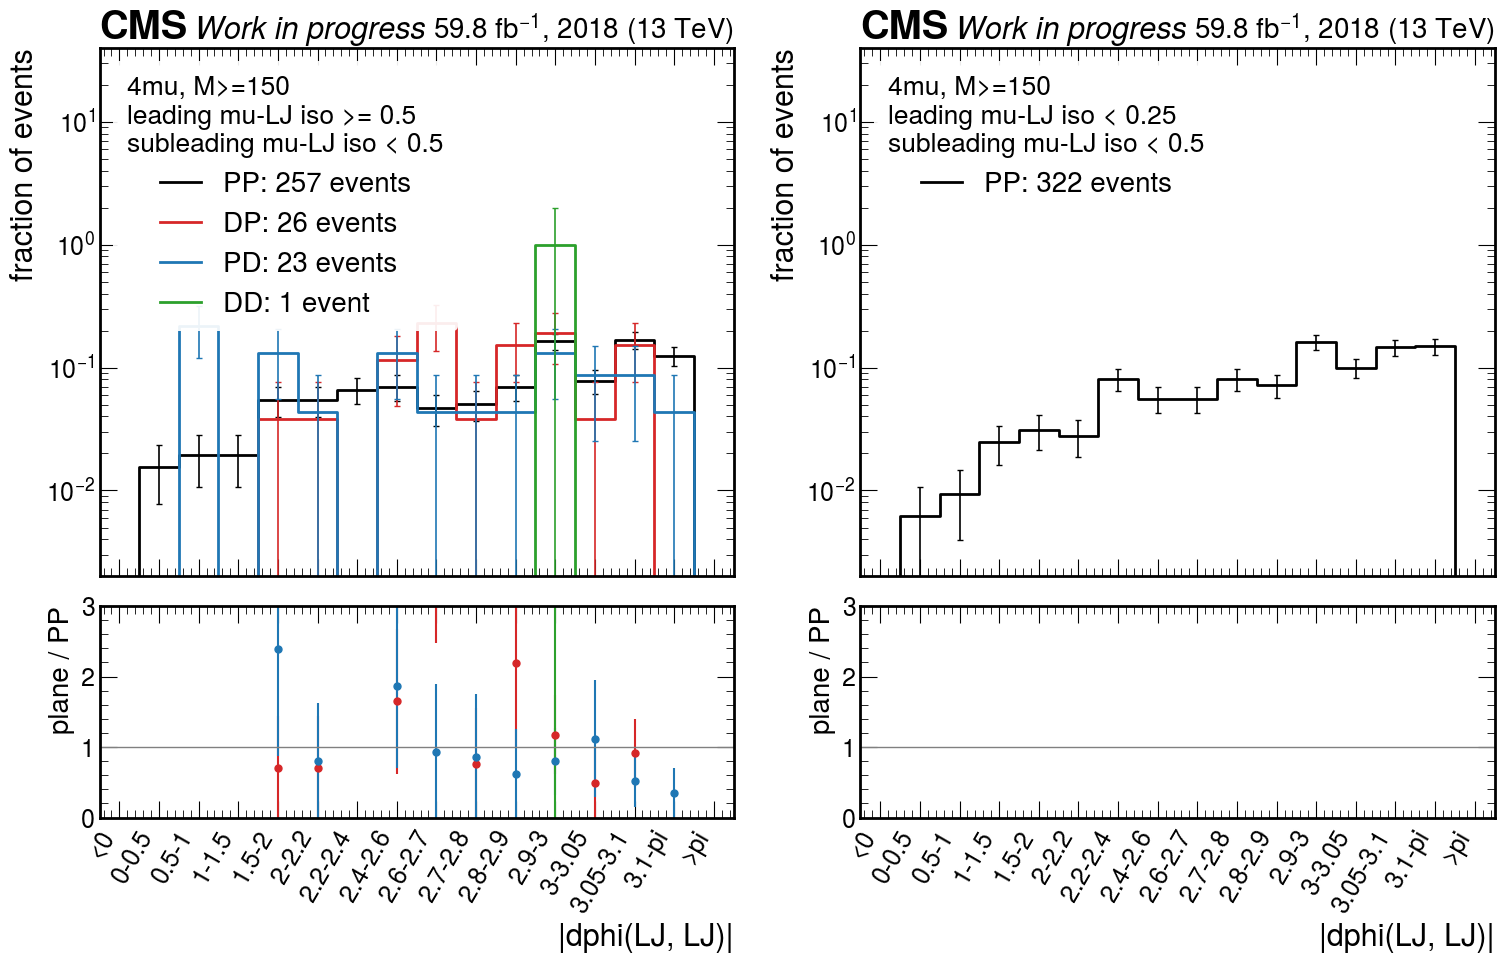

,shape,planes,events,chi2/ndf,p
0,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PP vs DP,257 vs 26,22.7/13,0.046
1,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PP vs PD,257 vs 23,31.0/13,0.003
2,"|dphi| where iso0 >= 0.5, iso1 < 0.5",PD vs DD,23 vs 1,5.2/10,0.876
3,"|dphi| where iso0 >= 0.5, iso1 < 0.5",DP vs DD,26 vs 1,3.6/8,0.888


In [5]:
for t in tl.TOPOLOGIES:
    fig = tp.dphi_shapes_figure(data[t], "M>=150")
    plt.show()
    display(tl.dphi_shape_table(data[t], "M>=150"))

### 1c. Closure where the isolated corner is open, and what the recipes give for the search region

Every prediction of A that a one-displacement transfer permits, tested in the planes whose A is
open: the one-LJ-displaced planes at M ≥ 150 GeV (from PP) and the DD plane at M < 150 GeV (from
PD and from DP, each one displacement away). The rows labelled "B C / D in the plane" are the
ordinary in-plane closure (κ) for reference. Observed over predicted is the closure; its
uncertainty combines the Poisson error of A with the factor's interval.

The second table lists what each recipe gives for the search region; A itself is not touched.
Every row states the assumption it rests on. Recipes that disagree with each other beyond their
uncertainties cannot all be right, which is a statement about the method that needs no
unblinding.

In [6]:
for t in tl.TOPOLOGIES:
    print(t)
    display(tl.dphi_closure_table(data[t]))
    display(tl.dphi_sr_prediction_table(data[t]))

2mu2e


,plane,mass,prediction of A,A observed,A predicted,observed / predicted
0,DP,M>=150,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP",44,39.3 ± 18.0,1.12 ± 0.54
1,DP,M>=150,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP",44,32.9 ± 15.2,1.34 ± 0.65
2,DP,M>=150,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP",44,50.3 -9.3 +9.9,0.88 ± 0.22
3,DP,M>=150,"B x A/B(PP): iso0 pass/fail ratio among |dphi| passes, taken from PP",44,42.2 ± 6.1,1.04 ± 0.22
4,DP,M>=150,B C / D in the plane (kappa = 1),44,38.6 ± 23.2,1.14 ± 0.71
5,PD,M>=150,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP",1343,1539.4 -180.1 +192.3,0.87 -0.11 +0.10
6,PD,M>=150,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP",1343,1291.0 -155.6 +167.0,1.04 -0.14 +0.13
7,PD,M>=150,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP",1343,824.7 -107.2 +121.6,1.63 -0.24 +0.22
8,PD,M>=150,"B x A/B(PP): iso0 pass/fail ratio among |dphi| passes, taken from PP",1343,691.6 ± 41.4,1.94 ± 0.13
9,PD,M>=150,B C / D in the plane (kappa = 1),1343,1065.4 ± 118.5,1.26 ± 0.14


,prediction of the search region A,value
0,B C / D in the plane; assumes kappa(DD) = 1,39.3 ± 16.8
1,"C x s(PD): |dphi| pass/fail ratio among iso0 failures, taken from PD; = B C / D x s(PD)/s(DD), assumes kappa(DD) = 1",59.8 ± 18.9
2,"C x s(DP): |dphi| pass/fail ratio among iso0 failures, taken from DP; = B C / D x s(DP)/s(DD), assumes kappa(DD) = 1",84.9 -40.6 +59.7
3,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP; = B C / D x s(PP)/s(DD), assumes kappa(DD) = 1",86.4 ± 27.5
4,"B x t(PD): iso0 pass/fail ratio among |dphi| failures, taken from PD; = B C / D x t(PD)/t(DD), assumes kappa(DD) = 1",60.1 ± 11.1
5,"B x t(DP): iso0 pass/fail ratio among |dphi| failures, taken from DP; = B C / D x t(DP)/t(DD), assumes kappa(DD) = 1",35.7 -19.7 +39.5
6,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP; = B C / D x t(PP)/t(DD), assumes kappa(DD) = 1",46.5 -8.8 +9.4
7,"C x A/C(PD): |dphi| pass/fail ratio among iso0 passes, taken from PD; assumes A/C is the same in DD",75.4 ± 23.6
8,"C x A/C(DP): |dphi| pass/fail ratio among iso0 passes, taken from DP; assumes A/C is the same in DD",96.8 -50.5 +84.8
9,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP; assumes A/C is the same in DD",72.5 ± 23.2


4mu


,plane,mass,prediction of A,A observed,A predicted,observed / predicted
0,DP,M>=150,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP",blind,28.3 ± 15.8,n/a
1,DP,M>=150,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP",blind,45.9 ± 26.2,n/a
2,DP,M>=150,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP",blind,19.7 -6.7 +8.4,n/a
3,DP,M>=150,"B x A/B(PP): iso0 pass/fail ratio among |dphi| passes, taken from PP",blind,32.0 ± 7.3,n/a
4,DP,M>=150,B C / D in the plane (kappa = 1),blind,96.0 ± 109.1,n/a
5,PD,M>=150,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP",blind,49.5 -21.1 +22.4,n/a
6,PD,M>=150,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP",blind,80.3 -34.8 +37.5,n/a
7,PD,M>=150,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP",blind,11.5 -4.4 +5.3,n/a
8,PD,M>=150,"B x A/B(PP): iso0 pass/fail ratio among |dphi| passes, taken from PP",blind,18.7 ± 5.3,n/a
9,PD,M>=150,B C / D in the plane (kappa = 1),blind,12.2 ± 7.1,n/a


,prediction of the search region A,value
0,B C / D in the plane; assumes kappa(DD) = 1,n/a
1,"C x s(PD): |dphi| pass/fail ratio among iso0 failures, taken from PD; = B C / D x s(PD)/s(DD), assumes kappa(DD) = 1",0.0 -0.0 +3.2
2,"C x s(DP): |dphi| pass/fail ratio among iso0 failures, taken from DP; = B C / D x s(DP)/s(DD), assumes kappa(DD) = 1",0.0 -0.0 +44.2
3,"C x s(PP): |dphi| pass/fail ratio among iso0 failures, taken from PP; = B C / D x s(PP)/s(DD), assumes kappa(DD) = 1",0.0 -0.0 +13.0
4,"B x t(PD): iso0 pass/fail ratio among |dphi| failures, taken from PD; = B C / D x t(PD)/t(DD), assumes kappa(DD) = 1",0.9 -0.9 +1.2
5,"B x t(DP): iso0 pass/fail ratio among |dphi| failures, taken from DP; = B C / D x t(DP)/t(DD), assumes kappa(DD) = 1",4.0 -4.0 +24.8
6,"B x t(PP): iso0 pass/fail ratio among |dphi| failures, taken from PP; = B C / D x t(PP)/t(DD), assumes kappa(DD) = 1",0.8 -0.8 +0.9
7,"C x A/C(PD): |dphi| pass/fail ratio among iso0 passes, taken from PD; assumes A/C is the same in DD",n/a
8,"C x A/C(DP): |dphi| pass/fail ratio among iso0 passes, taken from DP; assumes A/C is the same in DD",n/a
9,"C x A/C(PP): |dphi| pass/fail ratio among iso0 passes, taken from PP; assumes A/C is the same in DD",0.0 -0.0 +21.1


## 2. The companion plane: the two LJ isolations

### 2a. The four planes

The same table for the plane of the two isolations at $|\Delta\phi| \ge 2$. Here the two axes
belong to two different objects, so a ratio measures one LJ's isolation response while the other
LJ's displacement is varied, and a change between planes points at a physical population.

In [7]:
for t in tl.TOPOLOGIES:
    print(t, "— planes:", "; ".join(f"{p}: {tl.plane_label(t, p)}" for p in tl.PLANES))
    display(tl.region_table(data[t]))

2mu2e — planes: PP: mu-LJ prompt, EGM-LJ prompt; DP: mu-LJ displaced, EGM-LJ prompt; PD: mu-LJ prompt, EGM-LJ displaced; DD: mu-LJ displaced, EGM-LJ displaced


,mass,plane,A,B,C,D,r1 = B/D,ac = A/C,r0 = C/D,ab = A/B,B C / D,kappa,min N_eff
0,M>=150,PP,481,697,1056,1464,0.476 ± 0.023,0.455 -0.025 +0.026,0.721 ± 0.030,0.690 -0.041 +0.043,502.8 ± 27.8,0.957 ± 0.069,481
1,M>=150,DP,38,41,42,91,0.451 -0.084 +0.102,0.905 -0.199 +0.255,0.462 -0.085 +0.104,0.927 -0.205 +0.263,18.9 ± 4.6,2.008 ± 0.587,38
2,M>=150,PD,1142,737,483,431,1.710 -0.104 +0.110,2.364 -0.128 +0.136,1.121 -0.074 +0.079,1.550 ± 0.077,825.9 ± 62.6,1.383 ± 0.113,431
3,M>=150,DD,blind,43,22,18,2.389 -0.648 +0.906,n/a,1.222 -0.375 +0.544,n/a,52.6 ± 18.5,n/a,18
4,M<150,PP,194,330,846,1187,0.278 -0.017 +0.018,0.229 -0.018 +0.020,0.713 ± 0.034,0.588 -0.053 +0.058,235.2 ± 16.7,0.825 ± 0.083,194
5,M<150,DP,13,17,37,56,0.304 -0.083 +0.111,0.351 -0.110 +0.157,0.661 -0.138 +0.174,0.765 -0.270 +0.414,11.2 ± 3.6,1.157 ± 0.492,13
6,M<150,PD,719,347,464,350,0.991 -0.075 +0.081,1.550 -0.092 +0.098,1.326 -0.094 +0.101,2.072 -0.135 +0.145,460.0 ± 40.9,1.563 ± 0.151,347
7,M<150,DD,29,15,23,18,0.833 -0.280 +0.420,1.261 -0.342 +0.472,1.278 -0.388 +0.561,1.933 -0.591 +0.866,19.2 ± 7.8,1.513 ± 0.677,15


4mu — planes: PP: leading mu-LJ prompt, subleading mu-LJ prompt; DP: leading mu-LJ displaced, subleading mu-LJ prompt; PD: leading mu-LJ prompt, subleading mu-LJ displaced; DD: leading mu-LJ displaced, subleading mu-LJ displaced


,mass,plane,A,B,C,D,r1 = B/D,ac = A/C,r0 = C/D,ab = A/B,B C / D,kappa,min N_eff
0,M>=150,PP,190,70,317,972,0.072 -0.009 +0.010,0.599 -0.055 +0.060,0.326 -0.021 +0.023,2.714 -0.376 +0.439,22.8 ± 3.1,8.323 ± 1.282,70
1,M>=150,DP,blind,12,38,103,0.117 -0.035 +0.048,n/a,0.369 -0.069 +0.085,n/a,4.4 ± 1.5,n/a,12
2,M>=150,PD,blind,6,17,89,0.067 -0.027 +0.042,n/a,0.191 -0.050 +0.066,n/a,1.1 ± 0.6,n/a,6
3,M>=150,DD,blind,1,3,17,0.059 -0.049 +0.149,n/a,0.176 -0.102 +0.202,n/a,0.2 ± 0.2,n/a,1
4,M<150,PP,202,144,373,1941,0.074 -0.006 +0.007,0.542 -0.047 +0.052,0.192 -0.011 +0.011,1.403 -0.152 +0.171,27.7 ± 2.8,7.300 ± 0.897,144
5,M<150,DP,23,12,20,156,0.077 -0.023 +0.031,1.150 -0.340 +0.485,0.128 -0.030 +0.038,1.917 -0.649 +1.005,1.5 ± 0.6,14.950 ± 6.399,12
6,M<150,PD,12,16,36,145,0.110 -0.029 +0.038,0.333 -0.108 +0.155,0.248 -0.046 +0.056,0.750 -0.274 +0.427,4.0 ± 1.2,3.021 ± 1.283,12
7,M<150,DD,2,0,3,20,0.000 -0.000 +0.096,0.667 -0.495 +1.705,0.150 -0.086 +0.168,n/a,n/a,n/a,0


### 2b. Each LJ's isolation ratio across the other LJ's displacement

The pairs that matter: the object-1 ratios (r1 = B/D among object-0 failures, A/C among its
passes) compared between PP and DP and between PD and DD, i.e. with object 1 held in one state
while object 0 switches from prompt to displaced; the object-0 ratios (r0 = C/D, A/B) the other
way round. The same ratio across its own object's displacement is a different population (prompt
fakes against conversions, heavy-flavour decays and standalone-only muons) and is not expected
to transfer; it is not tabulated, but section 2d scans it.

In [8]:
for t in tl.TOPOLOGIES:
    for mass in ("M>=150", "M<150"):
        print(f"{t}, {mass}")
        display(tl.transfer_table(data[t], mass))

2mu2e, M>=150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,"r1 = B/D (EGM-LJ pass/fail ratio, mu-LJ fail)",mu-LJ: PP -> DP,"B=697, D=1464",0.476 ± 0.023,"B=41, D=91",0.451 -0.084 +0.102,0.946 -0.182 +0.219
1,"r1 = B/D (EGM-LJ pass/fail ratio, mu-LJ fail)",mu-LJ: PD -> DD,"B=737, D=431",1.710 -0.104 +0.110,"B=43, D=18",2.389 -0.648 +0.906,1.397 -0.390 +0.537
2,"ac = A/C (EGM-LJ pass/fail ratio, mu-LJ pass)",mu-LJ: PP -> DP,"A=481, C=1056",0.455 -0.025 +0.026,"A=38, C=42",0.905 -0.199 +0.255,1.986 -0.452 +0.571
3,"ac = A/C (EGM-LJ pass/fail ratio, mu-LJ pass)",mu-LJ: PD -> DD,"A=1142, C=483",2.364 -0.128 +0.136,"A=blind, C=22",n/a,n/a
4,"r0 = C/D (mu-LJ pass/fail ratio, EGM-LJ fail)",EGM-LJ: PP -> PD,"C=1056, D=1464",0.721 ± 0.030,"C=483, D=431",1.121 -0.074 +0.079,1.554 ± 0.127
5,"r0 = C/D (mu-LJ pass/fail ratio, EGM-LJ fail)",EGM-LJ: DP -> DD,"C=42, D=91",0.462 -0.085 +0.104,"C=22, D=18",1.222 -0.375 +0.544,2.648 -1.007 +1.275
6,"ab = A/B (mu-LJ pass/fail ratio, EGM-LJ pass)",EGM-LJ: PP -> PD,"A=481, B=697",0.690 -0.041 +0.043,"A=1142, B=737",1.550 ± 0.077,2.245 ± 0.177
7,"ab = A/B (mu-LJ pass/fail ratio, EGM-LJ pass)",EGM-LJ: DP -> DD,"A=38, B=41",0.927 -0.205 +0.263,"A=blind, B=43",n/a,n/a


2mu2e, M<150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,"r1 = B/D (EGM-LJ pass/fail ratio, mu-LJ fail)",mu-LJ: PP -> DP,"B=330, D=1187",0.278 -0.017 +0.018,"B=17, D=56",0.304 -0.083 +0.111,1.092 -0.306 +0.404
1,"r1 = B/D (EGM-LJ pass/fail ratio, mu-LJ fail)",mu-LJ: PD -> DD,"B=347, D=350",0.991 -0.075 +0.081,"B=15, D=18",0.833 -0.280 +0.420,0.841 -0.291 +0.428
2,"ac = A/C (EGM-LJ pass/fail ratio, mu-LJ pass)",mu-LJ: PP -> DP,"A=194, C=846",0.229 -0.018 +0.020,"A=13, C=37",0.351 -0.110 +0.157,1.532 -0.499 +0.693
3,"ac = A/C (EGM-LJ pass/fail ratio, mu-LJ pass)",mu-LJ: PD -> DD,"A=719, C=464",1.550 -0.092 +0.098,"A=29, C=23",1.261 -0.342 +0.472,0.814 -0.227 +0.308
4,"r0 = C/D (mu-LJ pass/fail ratio, EGM-LJ fail)",EGM-LJ: PP -> PD,"C=846, D=1187",0.713 ± 0.034,"C=464, D=350",1.326 -0.094 +0.101,1.860 ± 0.164
5,"r0 = C/D (mu-LJ pass/fail ratio, EGM-LJ fail)",EGM-LJ: DP -> DD,"C=37, D=56",0.661 -0.138 +0.174,"C=23, D=18",1.278 -0.388 +0.561,1.934 -0.777 +0.940
6,"ab = A/B (mu-LJ pass/fail ratio, EGM-LJ pass)",EGM-LJ: PP -> PD,"A=194, B=330",0.588 -0.053 +0.058,"A=719, B=347",2.072 -0.135 +0.145,3.525 ± 0.418
7,"ab = A/B (mu-LJ pass/fail ratio, EGM-LJ pass)",EGM-LJ: DP -> DD,"A=13, B=17",0.765 -0.270 +0.414,"A=29, B=15",1.933 -0.591 +0.866,2.528 -1.571 +1.442


4mu, M>=150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,"r1 = B/D (subleading mu-LJ pass/fail ratio, leading mu-LJ fail)",leading mu-LJ: PP -> DP,"B=70, D=972",0.072 -0.009 +0.010,"B=12, D=103",0.117 -0.035 +0.048,1.618 -0.535 +0.693
1,"r1 = B/D (subleading mu-LJ pass/fail ratio, leading mu-LJ fail)",leading mu-LJ: PD -> DD,"B=6, D=89",0.067 -0.027 +0.042,"B=1, D=17",0.059 -0.049 +0.149,0.873 -0.873 +2.237
2,"ac = A/C (subleading mu-LJ pass/fail ratio, leading mu-LJ pass)",leading mu-LJ: PP -> DP,"A=190, C=317",0.599 -0.055 +0.060,"A=blind, C=38",n/a,n/a
3,"ac = A/C (subleading mu-LJ pass/fail ratio, leading mu-LJ pass)",leading mu-LJ: PD -> DD,"A=blind, C=17",n/a,"A=blind, C=3",n/a,n/a
4,"r0 = C/D (leading mu-LJ pass/fail ratio, subleading mu-LJ fail)",subleading mu-LJ: PP -> PD,"C=317, D=972",0.326 -0.021 +0.023,"C=17, D=89",0.191 -0.050 +0.066,0.586 -0.158 +0.205
5,"r0 = C/D (leading mu-LJ pass/fail ratio, subleading mu-LJ fail)",subleading mu-LJ: DP -> DD,"C=38, D=103",0.369 -0.069 +0.085,"C=3, D=17",0.176 -0.102 +0.202,0.478 -0.297 +0.556
6,"ab = A/B (leading mu-LJ pass/fail ratio, subleading mu-LJ pass)",subleading mu-LJ: PP -> PD,"A=190, B=70",2.714 -0.376 +0.439,"A=blind, B=6",n/a,n/a
7,"ab = A/B (leading mu-LJ pass/fail ratio, subleading mu-LJ pass)",subleading mu-LJ: DP -> DD,"A=blind, B=12",n/a,"A=blind, B=1",n/a,n/a


4mu, M<150


,factor,varied,"counts, prompt","value, prompt","counts, displaced","value, displaced",displaced / prompt
0,"r1 = B/D (subleading mu-LJ pass/fail ratio, leading mu-LJ fail)",leading mu-LJ: PP -> DP,"B=144, D=1941",0.074 -0.006 +0.007,"B=12, D=156",0.077 -0.023 +0.031,1.037 -0.321 +0.424
1,"r1 = B/D (subleading mu-LJ pass/fail ratio, leading mu-LJ fail)",leading mu-LJ: PD -> DD,"B=16, D=145",0.110 -0.029 +0.038,"B=0, D=20",0.000 -0.000 +0.096,0.000 -0.000 +0.874
2,"ac = A/C (subleading mu-LJ pass/fail ratio, leading mu-LJ pass)",leading mu-LJ: PP -> DP,"A=202, C=373",0.542 -0.047 +0.052,"A=23, C=20",1.150 -0.340 +0.485,2.124 -0.660 +0.915
3,"ac = A/C (subleading mu-LJ pass/fail ratio, leading mu-LJ pass)",leading mu-LJ: PD -> DD,"A=12, C=36",0.333 -0.108 +0.155,"A=2, C=3",0.667 -0.495 +1.705,2.000 -1.752 +5.155
4,"r0 = C/D (leading mu-LJ pass/fail ratio, subleading mu-LJ fail)",subleading mu-LJ: PP -> PD,"C=373, D=1941",0.192 -0.011 +0.011,"C=36, D=145",0.248 -0.046 +0.056,1.292 -0.251 +0.299
5,"r0 = C/D (leading mu-LJ pass/fail ratio, subleading mu-LJ fail)",subleading mu-LJ: DP -> DD,"C=20, D=156",0.128 -0.030 +0.038,"C=3, D=20",0.150 -0.086 +0.168,1.170 -0.756 +1.339
6,"ab = A/B (leading mu-LJ pass/fail ratio, subleading mu-LJ pass)",subleading mu-LJ: PP -> PD,"A=202, B=144",1.403 -0.152 +0.171,"A=12, B=16",0.750 -0.274 +0.427,0.535 -0.206 +0.310
7,"ab = A/B (leading mu-LJ pass/fail ratio, subleading mu-LJ pass)",subleading mu-LJ: DP -> DD,"A=23, B=12",1.917 -0.649 +1.005,"A=2, B=0",n/a,n/a


Each panel shows the isolation distribution of the measured LJ inside the other LJ's fail slice
(isolation ≥ 0.5), normalised to unit area, for the two planes that differ only in the other LJ's
displacement. Top row: object 1's isolation (r1 pairs); bottom row: object 0's (r0 pairs). The
ratio panel is displaced over prompt; a flat ratio at 1 is a transferable shape, and the bins
below 0.25 (the pass region) are the ones that set the factor. Bins with no event in the displaced
plane are not drawn in the ratio panel. The table gives the pooled two-sample χ².

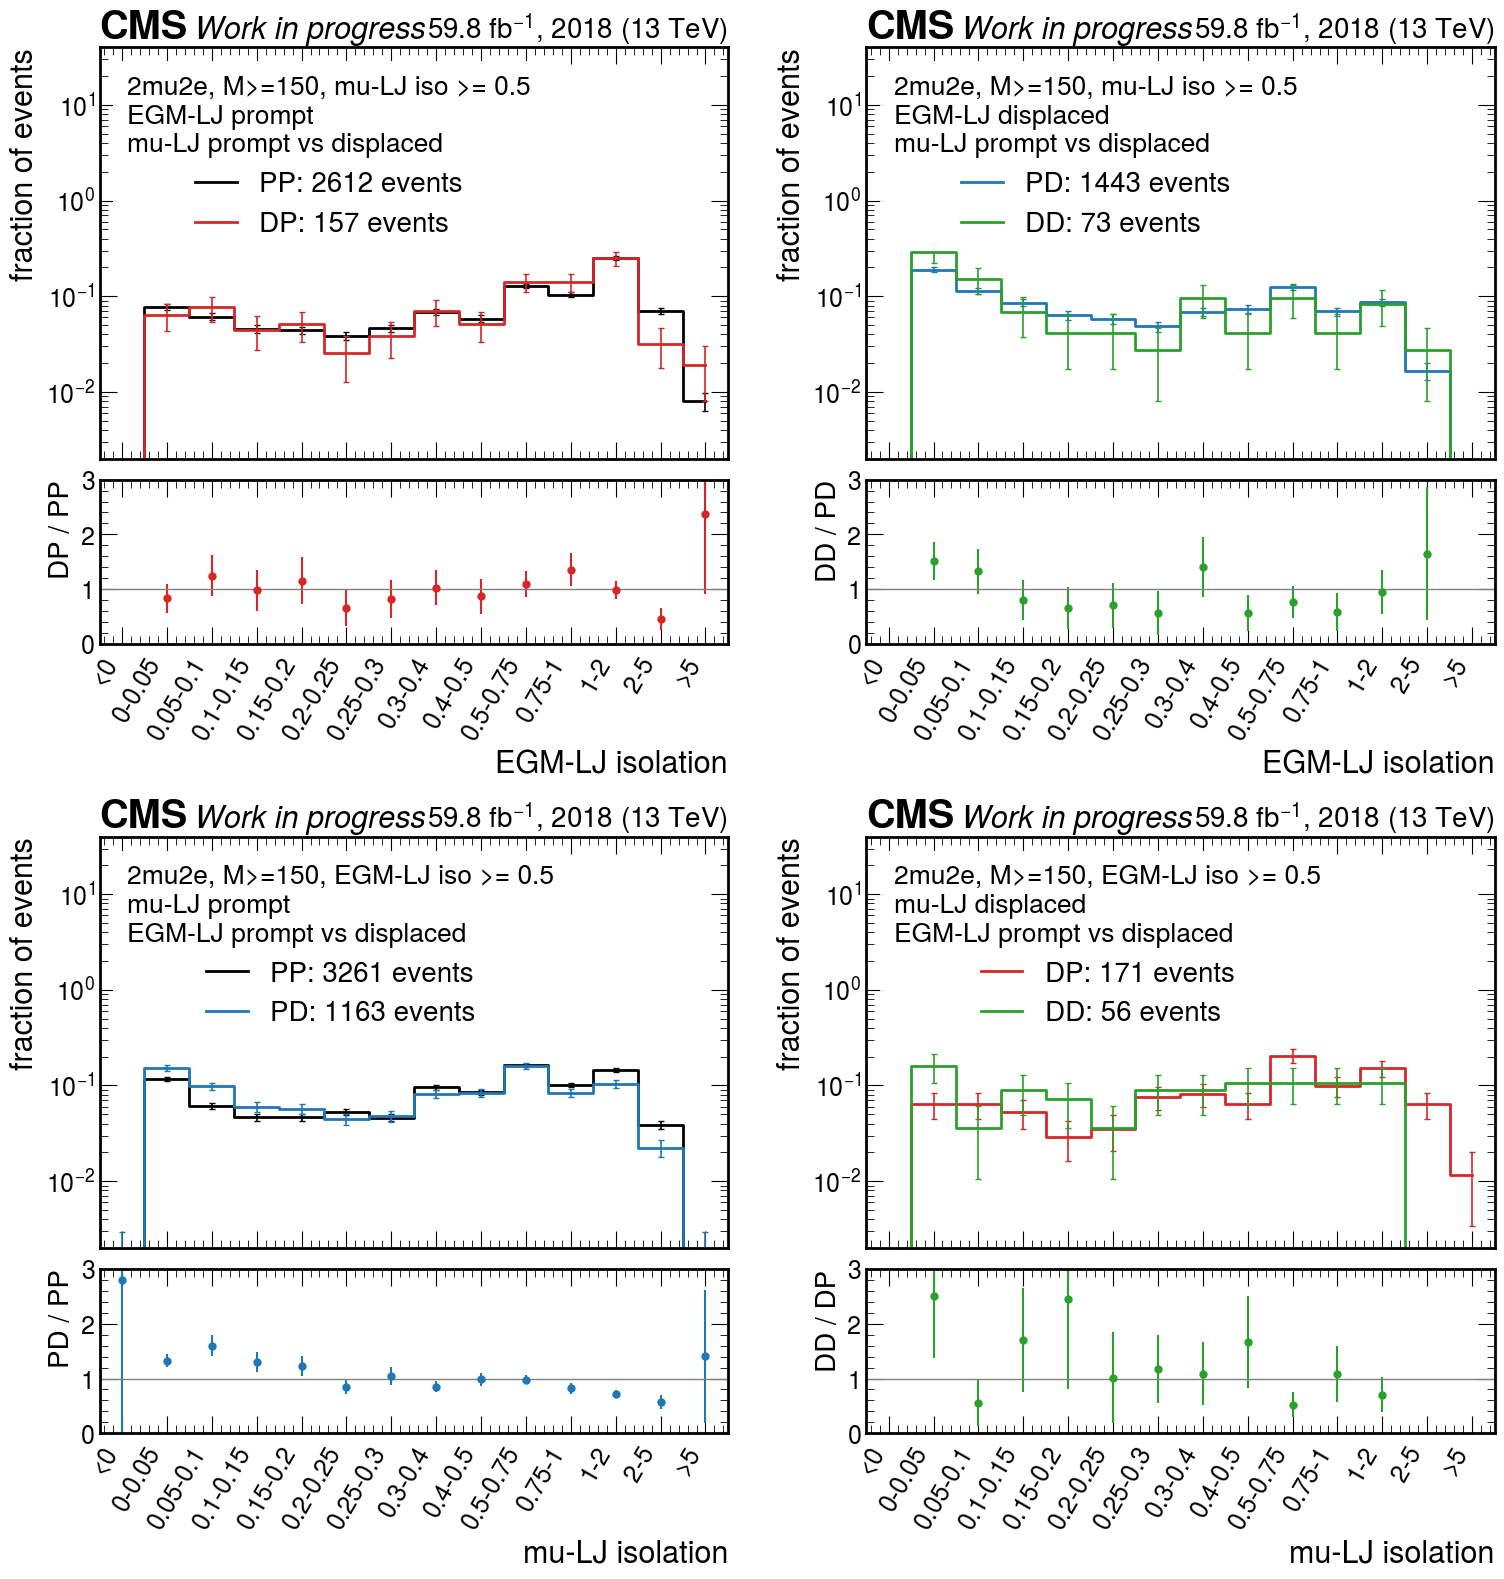

,shape,planes,events,chi2/ndf,p
0,iso1 where iso0 >= 0.5,PP vs DP,2612 vs 157,9.6/13,0.730
1,iso1 where iso0 >= 0.5,PD vs DD,1443 vs 73,9.6/11,0.567
2,iso0 where iso1 >= 0.5,PP vs PD,3261 vs 1163,55.8/13,0.000
3,iso0 where iso1 >= 0.5,DP vs DD,171 vs 56,16.1/12,0.186


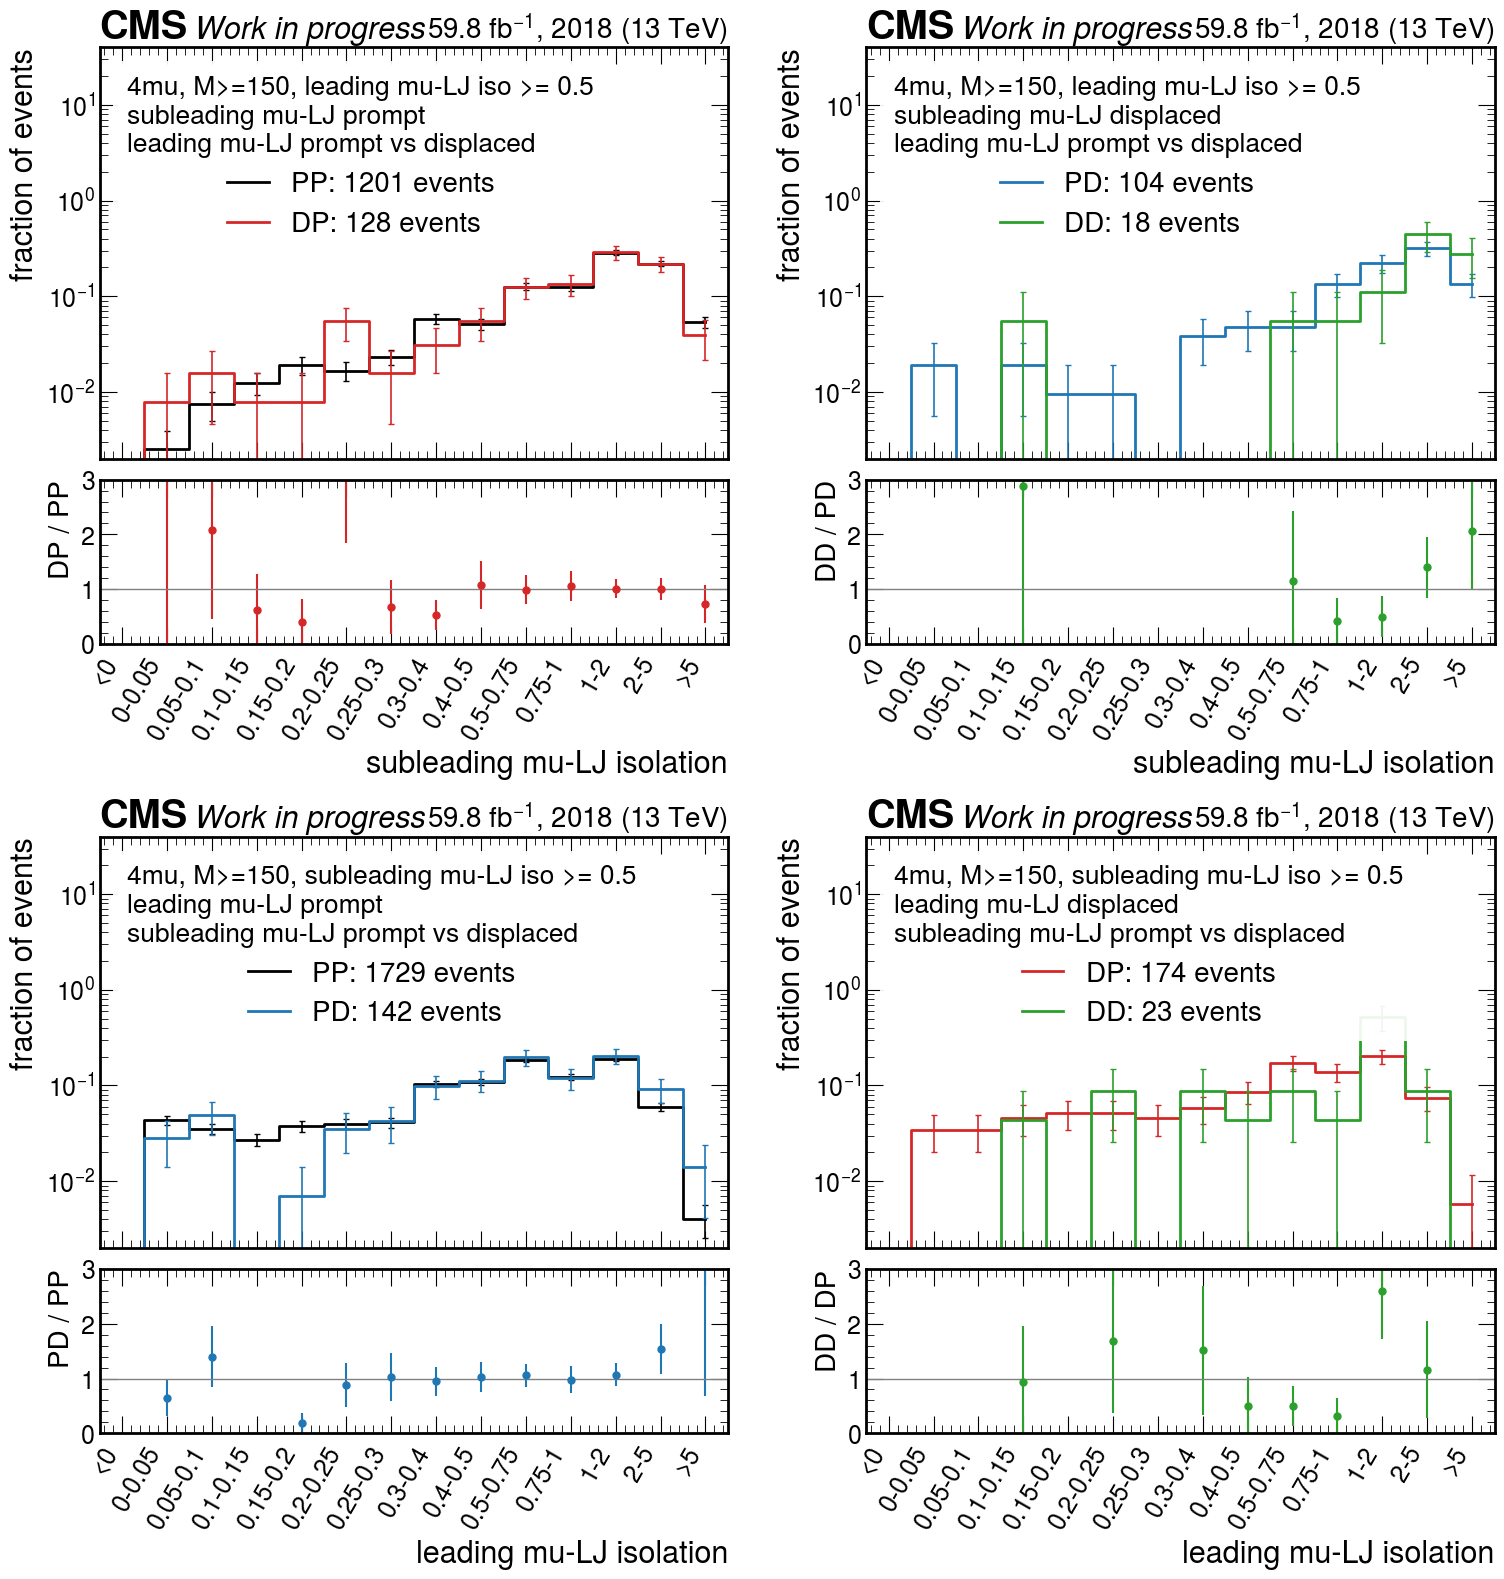

,shape,planes,events,chi2/ndf,p
0,iso1 where iso0 >= 0.5,PP vs DP,1201 vs 128,13.6/12,0.324
1,iso1 where iso0 >= 0.5,PD vs DD,104 vs 18,7.5/10,0.674
2,iso0 where iso1 >= 0.5,PP vs PD,1729 vs 142,14.0/12,0.299
3,iso0 where iso1 >= 0.5,DP vs DD,174 vs 23,16.3/12,0.178


In [9]:
for t in tl.TOPOLOGIES:
    fig = tp.fail_slice_shapes_figure(data[t], "M>=150")
    plt.show()
    display(tl.shape_table(data[t], "M>=150"))

### 2c. The ratios against the displacement variable itself

Instead of two states, the full displacement variable of the held object: left column, the
object-1 ratios in bins of object 0's pixel hits with object 1 held prompt (black) or displaced
(red), r1 among object-0 failures above and A/C among its passes below; right column, the
object-0 ratios in bins of object 1's lost hits (2μ2e; the last bin is the photon-only LJs, which
carry the sentinel 999) or pixel hits (4μ). Green bins are the displaced ones. The numbers under
each bin are the numerator and denominator counts ("blind" where the hidden box is touched). A
transferable ratio is flat across the green/white boundary; a ratio that changes inside the
displaced bins (for instance between zero pixel hits, where standalone-only muon LJs sit, and one
or two) says which population drives the change.

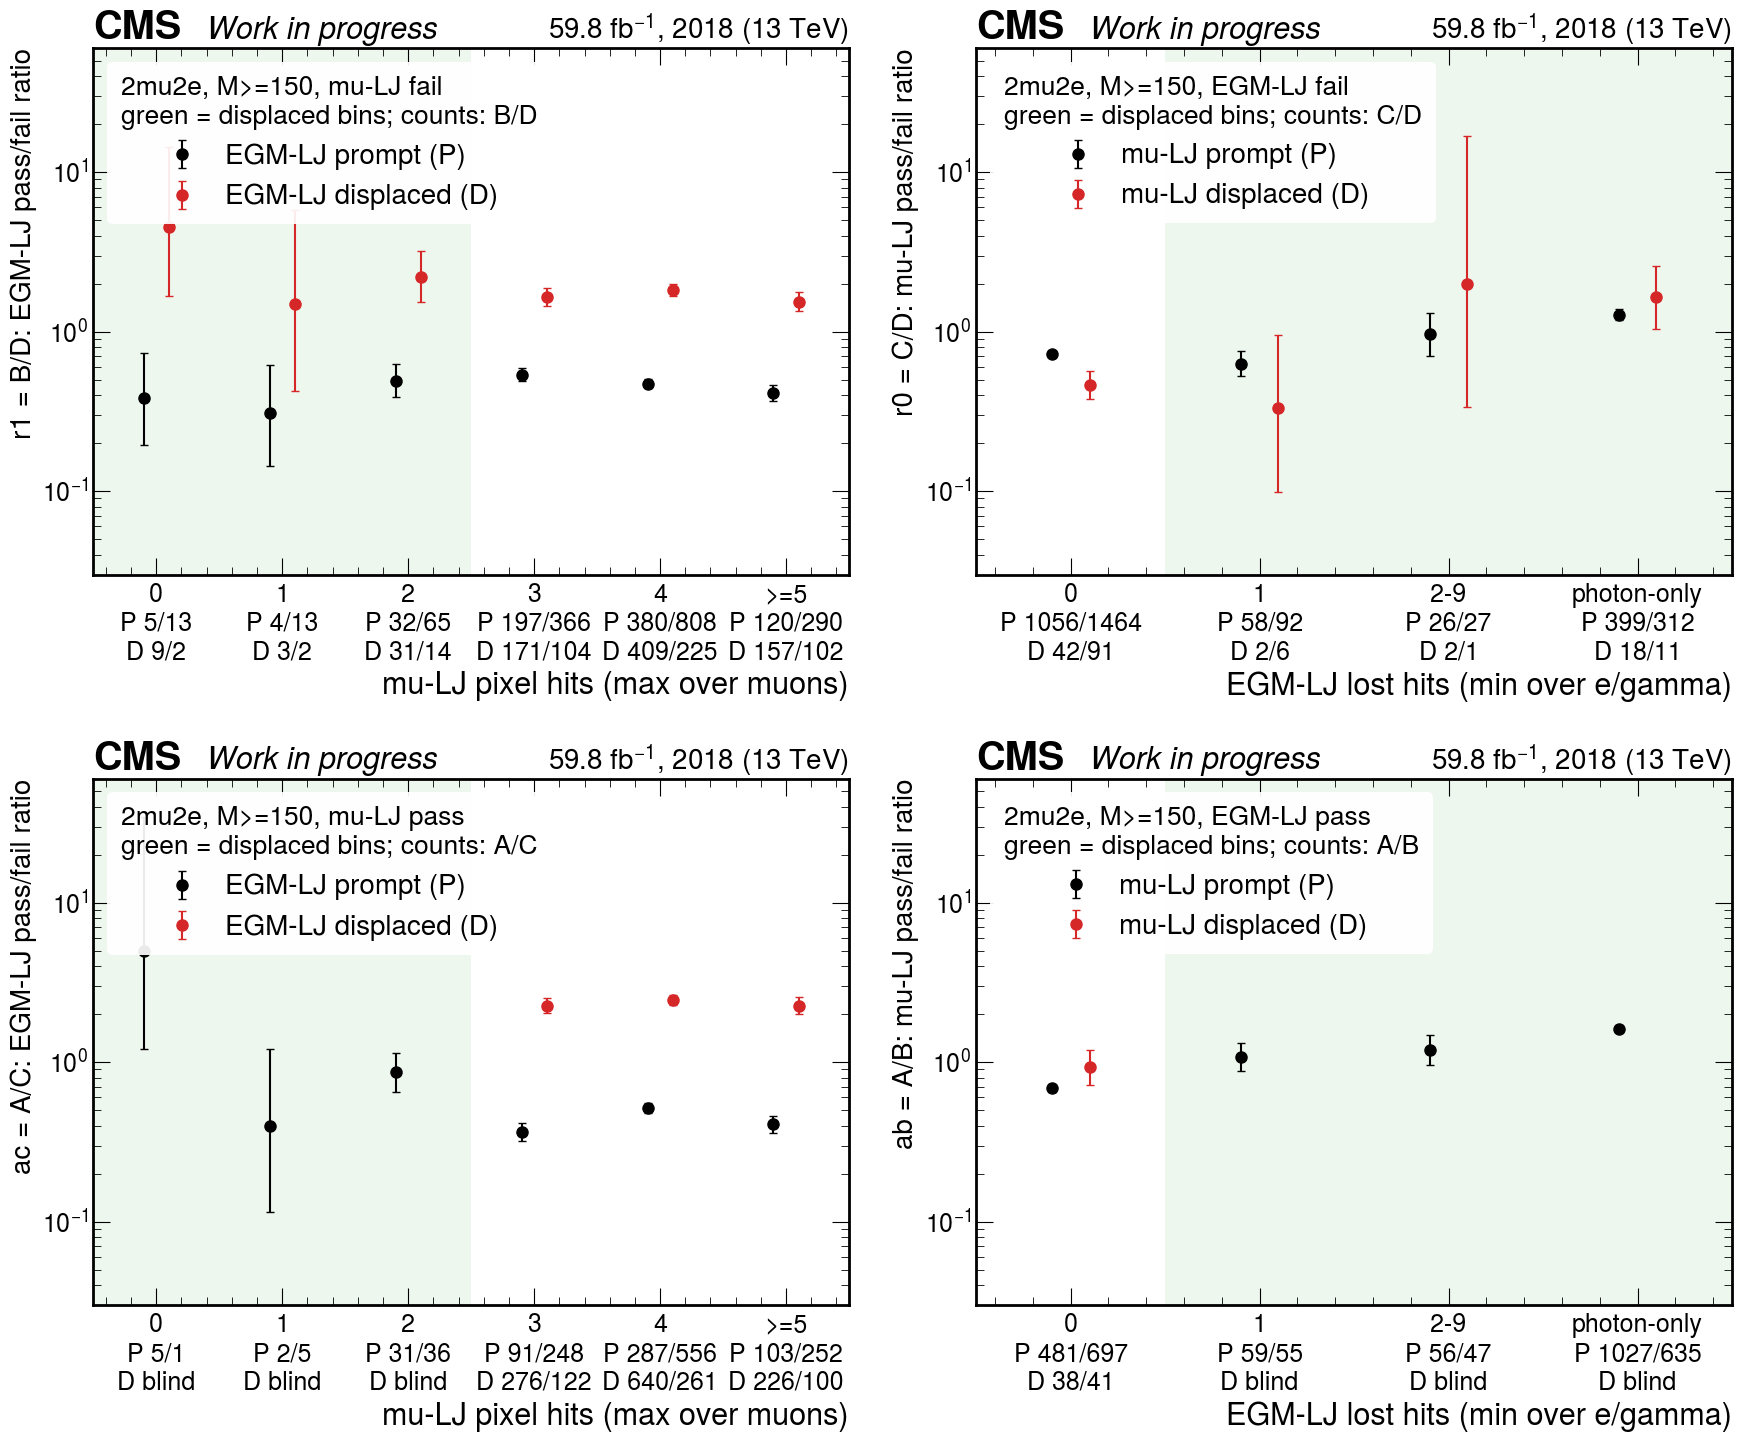

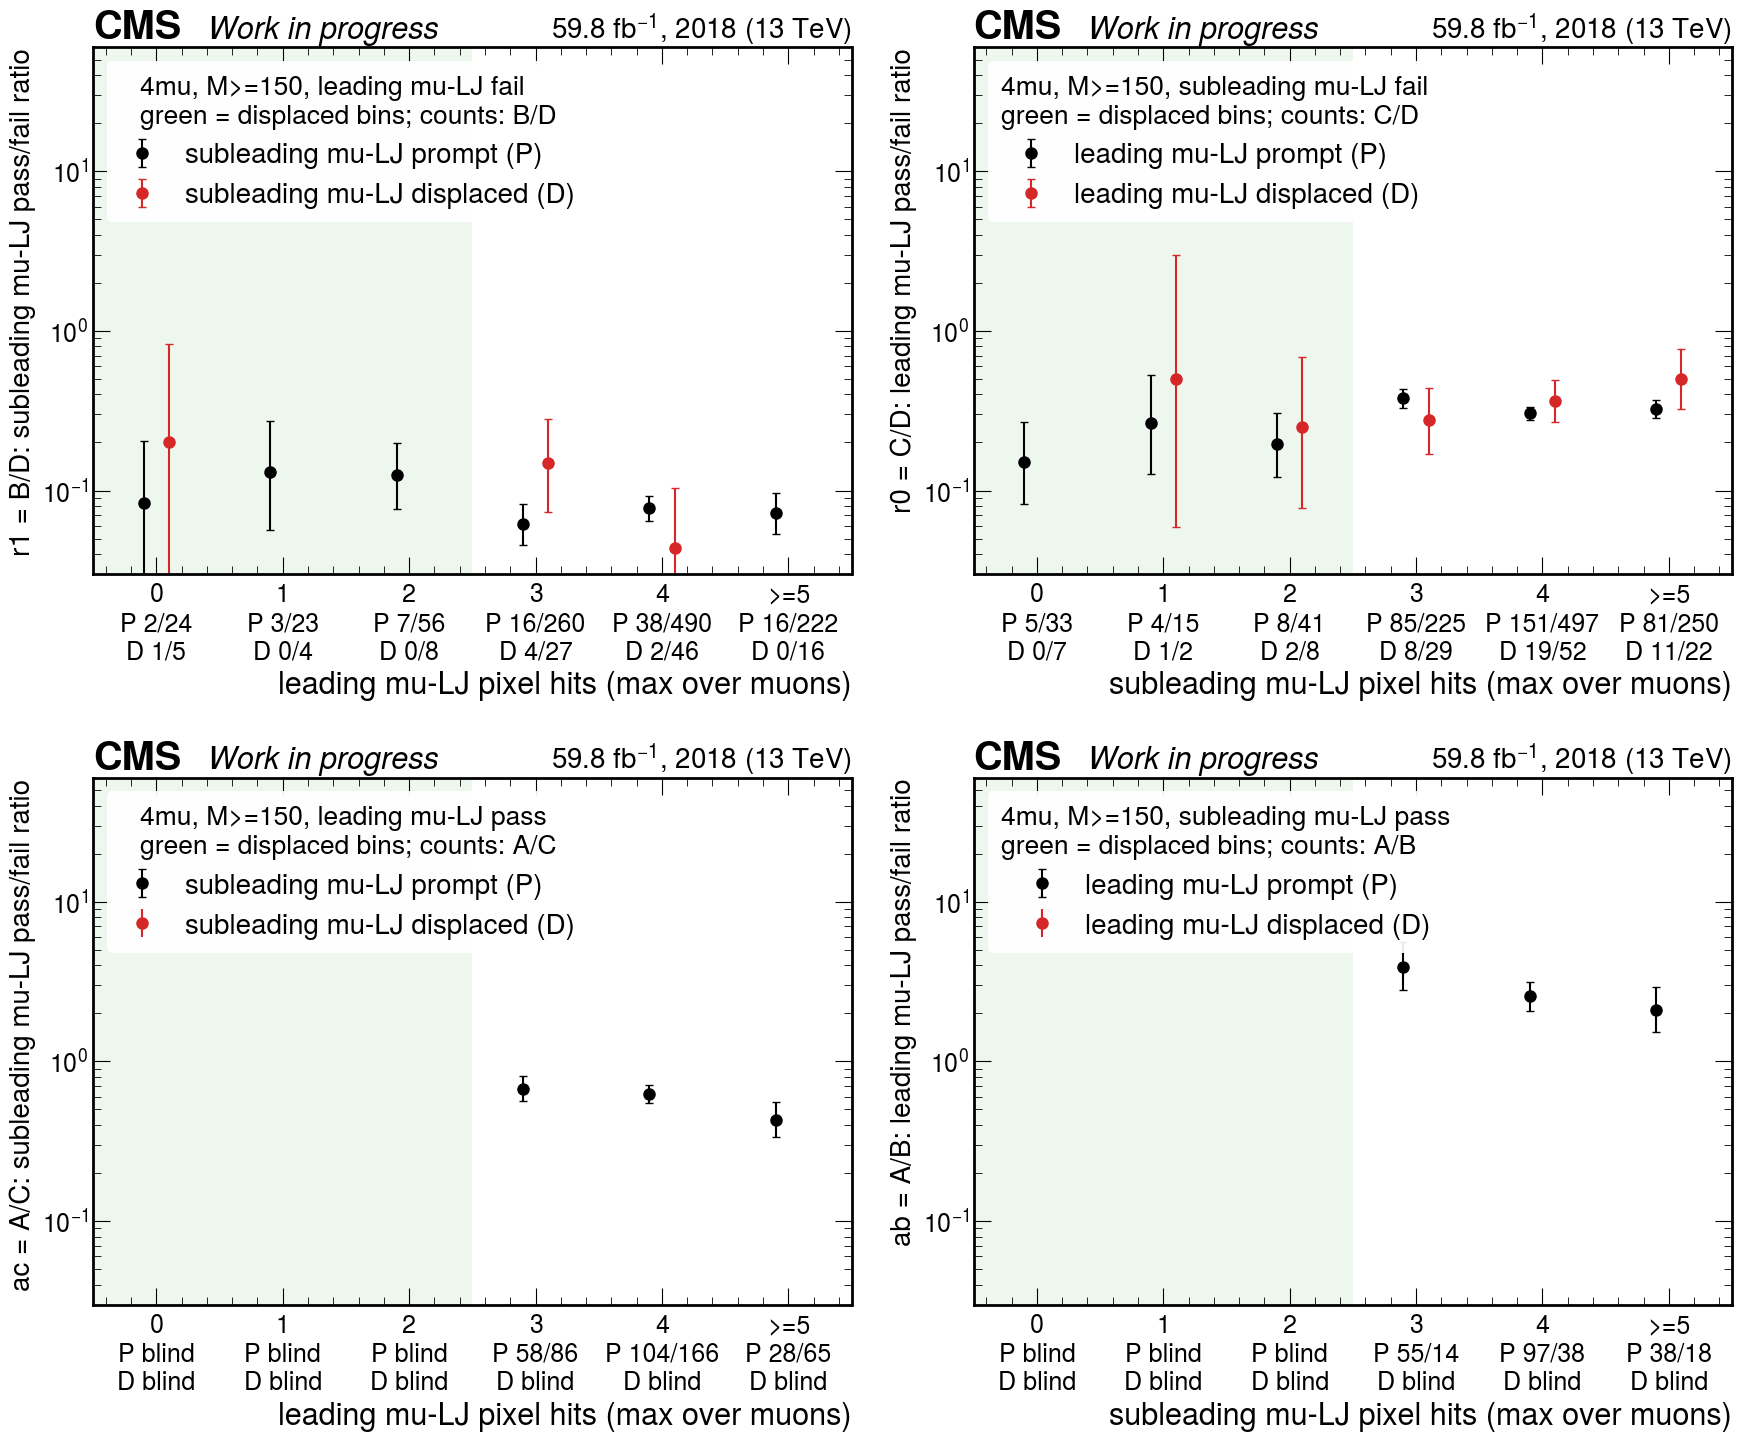

In [10]:
for t in tl.TOPOLOGIES:
    fig = tp.factor_scan_figure(data[t], "M>=150")
    plt.show()

### 2d. Closure where the isolated corner is open, and the recipes for the isolated DD corner

As in section 1c, for the companion plane. The isolated DD corner of this plane at M ≥ 150 GeV
is not the search region (the analysis plane's A is), but it is inside the hidden box and its
recipes are listed with their assumptions in the same way.

In [11]:
for t in tl.TOPOLOGIES:
    print(t)
    display(tl.closure_table(data[t]))
    display(tl.sr_prediction_table(data[t]))

2mu2e


,plane,mass,prediction of A,A observed,A predicted,observed / predicted
0,DP,M>=150,"C x r1(PP): EGM-LJ pass/fail ratio among mu-LJ failures, taken across mu-LJ displacement",38,20.0 ± 3.2,1.90 ± 0.44
1,DP,M>=150,"C x ac(PP): EGM-LJ pass/fail ratio among mu-LJ passes, taken across mu-LJ displacement",38,19.1 ± 3.2,1.99 ± 0.46
2,DP,M>=150,B C / D in the plane (kappa = 1),38,18.9 ± 4.6,2.01 ± 0.59
3,PD,M>=150,"B x r0(PP): mu-LJ pass/fail ratio among EGM-LJ failures, taken across EGM-LJ displacement",1142,531.6 ± 29.7,2.15 ± 0.14
4,PD,M>=150,"B x ab(PP): mu-LJ pass/fail ratio among EGM-LJ passes, taken across EGM-LJ displacement",1142,508.6 ± 37.1,2.25 ± 0.18
5,PD,M>=150,B C / D in the plane (kappa = 1),1142,825.9 ± 62.6,1.38 ± 0.11
6,DD,M<150,"C x r1(PD): EGM-LJ pass/fail ratio among mu-LJ failures, taken across mu-LJ displacement",29,22.8 ± 5.1,1.27 ± 0.37
7,DD,M<150,"C x ac(PD): EGM-LJ pass/fail ratio among mu-LJ passes, taken across mu-LJ displacement",29,35.6 ± 7.8,0.81 ± 0.23
8,DD,M<150,"B x r0(DP): mu-LJ pass/fail ratio among EGM-LJ failures, taken across EGM-LJ displacement",29,9.9 -3.3 +3.7,2.93 -1.21 +1.11
9,DD,M<150,"B x ab(DP): mu-LJ pass/fail ratio among EGM-LJ passes, taken across EGM-LJ displacement",29,11.5 -5.0 +6.9,2.53 -1.59 +1.20


,"prediction of A (DD, M>=150)",value
0,B C / D in the plane; assumes kappa(DD) = 1,52.6 ± 18.5
1,"C x r1(PD): EGM-LJ pass/fail ratio among mu-LJ failures, taken across mu-LJ displacement; = B C / D x r1(PD)/r1(DD), assumes kappa(DD) = 1",37.6 ± 8.4
2,"B x r0(DP): mu-LJ pass/fail ratio among EGM-LJ failures, taken across EGM-LJ displacement; = B C / D x r0(DP)/r0(DD), assumes kappa(DD) = 1",19.8 -4.8 +5.4
3,"C x ac(PD): EGM-LJ pass/fail ratio among mu-LJ passes, taken across mu-LJ displacement; assumes ac transfers across that displacement",52.0 ± 11.5
4,"B x ab(DP): mu-LJ pass/fail ratio among EGM-LJ passes, taken across EGM-LJ displacement; assumes ab transfers across that displacement",39.9 -10.7 +12.8
5,B C / D x kappa(PP); assumes kappa(DD) = kappa(PP),50.3 ± 18.1
6,B C / D x kappa(DP); assumes kappa(DD) = kappa(DP),105.5 ± 48.3
7,B C / D x kappa(PD); assumes kappa(DD) = kappa(PD),72.7 ± 26.3


4mu


,plane,mass,prediction of A,A observed,A predicted,observed / predicted
0,DP,M>=150,"C x r1(PP): subleading mu-LJ pass/fail ratio among leading mu-LJ failures, taken across leading mu-LJ displacement",blind,2.7 ± 0.6,n/a
1,DP,M>=150,"C x ac(PP): subleading mu-LJ pass/fail ratio among leading mu-LJ passes, taken across leading mu-LJ displacement",blind,22.8 ± 4.3,n/a
2,DP,M>=150,B C / D in the plane (kappa = 1),blind,4.4 ± 1.5,n/a
3,PD,M>=150,"B x r0(PP): leading mu-LJ pass/fail ratio among subleading mu-LJ failures, taken across subleading mu-LJ displacement",blind,2.0 ± 0.8,n/a
4,PD,M>=150,"B x ab(PP): leading mu-LJ pass/fail ratio among subleading mu-LJ passes, taken across subleading mu-LJ displacement",blind,16.3 ± 7.2,n/a
5,PD,M>=150,B C / D in the plane (kappa = 1),blind,1.1 ± 0.6,n/a
6,DD,M<150,"C x r1(PD): subleading mu-LJ pass/fail ratio among leading mu-LJ failures, taken across leading mu-LJ displacement",2,0.3 -0.2 +0.2,6.04 ± 5.89
7,DD,M<150,"C x ac(PD): subleading mu-LJ pass/fail ratio among leading mu-LJ passes, taken across leading mu-LJ displacement",2,1.0 -0.7 +0.7,2.00 ± 2.00
8,DD,M<150,"B x r0(DP): leading mu-LJ pass/fail ratio among subleading mu-LJ failures, taken across subleading mu-LJ displacement",2,0.0 -0.0 +0.2,n/a
9,DD,M<150,"B x ab(DP): leading mu-LJ pass/fail ratio among subleading mu-LJ passes, taken across subleading mu-LJ displacement",2,0.0 -0.0 +3.5,n/a


,"prediction of A (DD, M>=150)",value
0,B C / D in the plane; assumes kappa(DD) = 1,0.2 ± 0.2
1,"C x r1(PD): subleading mu-LJ pass/fail ratio among leading mu-LJ failures, taken across leading mu-LJ displacement; = B C / D x r1(PD)/r1(DD), assumes kappa(DD) = 1",0.2 -0.1 +0.2
2,"B x r0(DP): leading mu-LJ pass/fail ratio among subleading mu-LJ failures, taken across subleading mu-LJ displacement; = B C / D x r0(DP)/r0(DD), assumes kappa(DD) = 1",0.4 ± 0.4
3,"C x ac(PD): subleading mu-LJ pass/fail ratio among leading mu-LJ passes, taken across leading mu-LJ displacement; assumes ac transfers across that displacement",n/a
4,"B x ab(DP): leading mu-LJ pass/fail ratio among subleading mu-LJ passes, taken across subleading mu-LJ displacement; assumes ab transfers across that displacement",n/a
5,B C / D x kappa(PP); assumes kappa(DD) = kappa(PP),1.5 -1.5 +1.7
6,B C / D x kappa(DP); assumes kappa(DD) = kappa(DP),n/a
7,B C / D x kappa(PD); assumes kappa(DD) = kappa(PD),n/a


## 3. Simulation: the same tables, and what populates each region

The 18 background samples (QCD, Drell–Yan, tt̄, diboson), scaled to the 2018 luminosity. The
simulation decides nothing here: its DD plane holds a few effective events, and its
validation-plane κ has uncertainties of 50–100%, so it neither confirms nor contradicts the data.
The composition tables say which process each open region is made of, which is the physical
reason a ratio does or does not move between planes.

In [12]:
bkg = tl.group_cubes(BASE, "bkg")     # summed per process group: QCD, DY, ttbar, diboson
bkg_sum = {t: io.add_cubes([g[t] for g in bkg.values()]) for t in tl.TOPOLOGIES}
for t in tl.TOPOLOGIES:
    print(t, "— simulation, analysis plane, buffered regions")
    display(tl.dphi_table(bkg_sum[t]))
    print(t, "— simulation, companion plane, buffered regions")
    display(tl.region_table(bkg_sum[t]))
    for plane in tl.PLANES:
        print(f"{t} {plane} ({tl.plane_label(t, plane)}), M>=150: composition, analysis plane")
        display(tl.composition_table(bkg, t, plane, kind="dphi x iso0"))
        print(f"{t} {plane} ({tl.plane_label(t, plane)}), M>=150: composition, companion plane")
        display(tl.composition_table(bkg, t, plane))
del bkg

2mu2e — simulation, analysis plane, buffered regions


,mass,plane,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,M>=150,PP,1282.0 ± 577.9,1263.4 ± 184.2,52.2 ± 17.3,163.6 ± 73.5,7.723 ± 3.648,24.560 ± 13.728,0.319 ± 0.178,1.015 ± 0.481,403.1 ± 232.4,3.180 ± 2.327
1,M>=150,DP,18.9 ± 10.5,42.3 ± 11.6,3.4 ± 3.3,19.4 ± 9.3,2.182 ± 1.205,5.560 ± 6.181,0.175 ± 0.189,0.447 ± 0.277,7.4 ± 8.2,2.549 ± 3.164
2,M>=150,PD,477.5 ± 144.7,875.8 ± 151.6,378.7 ± 169.8,296.1 ± 121.3,2.958 ± 1.316,1.261 ± 0.682,1.279 ± 0.777,0.545 ± 0.190,1120.2 ± 707.4,0.426 ± 0.299
3,M>=150,DD,32.3 ± 14.7,153.9 ± 118.9,14.9 ± 10.4,14.9 ± 7.5,10.334 ± 9.547,2.161 ± 1.794,1.003 ± 0.861,0.210 ± 0.188,154.3 ± 178.3,0.209 ± 0.260
4,M<150,PP,616.2 ± 538.1,562.5 ± 207.3,328.6 ± 122.2,571.8 ± 46.5,0.984 ± 0.371,1.875 ± 1.780,0.575 ± 0.219,1.096 ± 1.038,323.3 ± 171.3,1.906 ± 1.947
5,M<150,DP,17.2 ± 9.3,17.8 ± 9.3,10.2 ± 5.7,41.6 ± 13.6,0.428 ± 0.263,1.687 ± 1.305,0.245 ± 0.158,0.965 ± 0.722,4.4 ± 3.6,3.938 ± 3.889
6,M<150,PD,69.5 ± 20.0,589.6 ± 161.9,467.9 ± 142.9,805.9 ± 162.9,0.732 ± 0.249,0.149 ± 0.062,0.581 ± 0.213,0.118 ± 0.047,342.3 ± 156.7,0.203 ± 0.110
7,M<150,DD,6.5 ± 4.6,19.9 ± 10.5,18.5 ± 9.3,27.3 ± 10.6,0.728 ± 0.478,0.353 ± 0.307,0.675 ± 0.429,0.328 ± 0.289,13.4 ± 11.1,0.485 ± 0.528


2mu2e — simulation, companion plane, buffered regions


,mass,plane,A,B,C,D,r1 = B/D,ac = A/C,r0 = C/D,ab = A/B,B C / D,kappa,min N_eff
0,M>=150,PP,528.0 ± 185.0,801.8 ± 132.2,748.8 ± 165.9,1790.5 ± 233.6,0.448 ± 0.094,0.705 ± 0.292,0.418 ± 0.108,0.659 ± 0.255,335.4 ± 102.4,1.575 ± 0.732,8
1,M>=150,DP,9.6 ± 7.4,40.2 ± 11.9,135.0 ± 118.6,299.6 ± 123.9,0.134 ± 0.068,0.071 ± 0.083,0.451 ± 0.438,0.238 ± 0.198,18.1 ± 18.4,0.528 ± 0.675,1
2,M>=150,PD,532.4 ± 185.3,1006.6 ± 213.8,320.4 ± 169.1,358.3 ± 80.9,2.809 ± 0.871,1.661 ± 1.051,0.894 ± 0.513,0.529 ± 0.216,900.2 ± 551.0,0.591 ± 0.416,4
3,M>=150,DD,27.6 ± 13.2,34.2 ± 11.2,0.0 ± 0.0,17.8 ± 8.3,1.922 ± 1.094,5373.693 ± 4580.352,0.000 ± 0.000,0.809 ± 0.467,0.0 ± 0.0,2796.011 ± 2865.870,2
4,M<150,PP,609.9 ± 537.9,212.2 ± 29.7,361.8 ± 169.8,1745.7 ± 591.7,0.122 ± 0.045,1.686 ± 1.684,0.207 ± 0.120,2.874 ± 2.567,44.0 ± 26.2,13.867 ± 14.759,1
5,M<150,DP,3.3 ± 3.3,14.5 ± 8.7,3.3 ± 3.2,586.8 ± 538.0,0.025 ± 0.027,1.007 ± 1.424,0.006 ± 0.008,0.226 ± 0.263,0.1 ± 0.1,40.721 ± 72.807,1
6,M<150,PD,79.3 ± 20.8,555.5 ± 173.6,46.5 ± 18.9,875.2 ± 260.6,0.635 ± 0.274,1.704 ± 0.824,0.053 ± 0.027,0.143 ± 0.058,29.5 ± 17.5,2.684 ± 1.740,6
7,M<150,DD,7.4 ± 4.7,13.5 ± 7.6,3.2 ± 3.2,16.2 ± 10.4,0.836 ± 0.711,2.274 ± 2.690,0.200 ± 0.238,0.546 ± 0.460,2.7 ± 3.6,2.721 ± 3.965,1


2mu2e PP (mu-LJ prompt, EGM-LJ prompt), M>=150: composition, analysis plane


...

,component,A,B,C,D
0,DY,9.7,0.0,0.0,0.0
1,QCD,8.1,11.0,6.1,127.3
2,diboson,0.0,0.0,0.0,0.0
3,ttbar,0.0,0.0,0.0,3.3
4,total,17.9 ± 9.3,11.0 ± 7.5,6.1 ± 1.9,130.5 ± 21.7
5,N_eff,4,2,10,36


4mu DD (leading mu-LJ displaced, subleading mu-LJ displaced), M>=150: composition, analysis plane


,component,A,B,C,D
0,DY,3.2,0.0,0.0,0.0
1,QCD,0.0,0.0,0.0,0.8
2,diboson,0.0,0.0,0.0,0.0
3,ttbar,0.0,0.0,3.3,0.0
4,total,3.3 ± 3.2,0.0 ± 0.0,3.3 ± 3.3,0.8 ± 0.7
5,N_eff,1,2,1,1


4mu DD (leading mu-LJ displaced, subleading mu-LJ displaced), M>=150: composition, companion plane


,component,A,B,C,D
0,DY,3.2,0.0,0.0,0.0
1,QCD,0.0,0.0,1.6,13.4
2,diboson,0.0,0.0,0.0,0.0
3,ttbar,0.0,0.0,0.0,0.0
4,total,3.3 ± 3.2,0.0 ± 0.0,1.6 ± 0.9,13.4 ± 7.5
5,N_eff,1,2,3,3


## 4. Signal in the open regions

Seven signal points per channel: the four reference points of the status report (m_A = 200,
500, 800, 1000 GeV with m_Zd = 0.25 GeV and a mean transverse decay length near 40 cm), two
m_Zd = 1.2 GeV points at the same decay length (800 and 1000 GeV) and the longer-lived
800 GeV, m_Zd = 0.25 GeV point near 190 cm. The stored normalisation is the production cross
section of the samples (not a limit-level one); the search-region yields at that normalisation
are listed first. For every region the table then gives the percentage of the signal's own
search-region yield that falls there, the largest signal count among the seven points and, where
the region is open, the data count and the largest signal-over-data count. The hidden regions
appear with their signal share and "blind" for the data: that share is what justifies hiding
them. A region used to measure a ratio is safe when the signal-over-data count it could hold is
small compared with the ratio's statistical precision. Signal in a region that enters a prediction
multiplicatively (C of the analysis plane in C × s, C of the companion plane in C × r1) is absorbed
into the background estimate as that percentage times the factor, at any cross section.

In [13]:
SIGNAL_POINTS = {"2mu2e": ["2Mu2E_200GeV_0p25GeV_1p0mm", "2Mu2E_500GeV_0p25GeV_0p4mm",
                           "2Mu2E_800GeV_0p25GeV_0p25mm", "2Mu2E_1000GeV_0p25GeV_0p2mm",
                           "2Mu2E_800GeV_1p2GeV_1p2mm", "2Mu2E_1000GeV_1p2GeV_0p96mm",
                           "2Mu2E_800GeV_0p25GeV_1p2mm"],
                 "4mu": ["4Mu_200GeV_0p25GeV_1p0mm", "4Mu_500GeV_0p25GeV_0p4mm",
                         "4Mu_800GeV_0p25GeV_0p25mm", "4Mu_1000GeV_0p25GeV_0p2mm",
                         "4Mu_800GeV_1p2GeV_1p2mm", "4Mu_1000GeV_1p2GeV_0p96mm",
                         "4Mu_800GeV_0p25GeV_1p2mm"]}
for t in tl.TOPOLOGIES:
    signals = tl.sample_cubes(BASE, "signal", SIGNAL_POINTS[t], topologies=(t,))
    short = {k.split("_", 1)[1]: v for k, v in signals.items()}
    print(t)
    display(tl.signal_sr_yields(short, t))
    display(tl.contamination_table(short, data[t], t))
    del signals, short

2mu2e


,signal,"search region (dphi plane A, DD, M>=150), stored normalisation",N_eff
0,1000GeV_0p25GeV_0p2mm,1.5 ± 0.0,14171
1,1000GeV_1p2GeV_0p96mm,2.1 ± 0.0,16225
2,200GeV_0p25GeV_1p0mm,0.6 ± 0.0,8538
3,500GeV_0p25GeV_0p4mm,14.9 ± 0.1,41125
4,800GeV_0p25GeV_0p25mm,59.5 ± 0.4,17817
5,800GeV_0p25GeV_1p2mm,21.5 ± 0.3,6831
6,800GeV_1p2GeV_1p2mm,63.2 ± 0.4,21314


,plane kind,mass,plane,region,data,1000GeV_0p25GeV_0p2mm,1000GeV_1p2GeV_0p96mm,200GeV_0p25GeV_1p0mm,500GeV_0p25GeV_0p4mm,800GeV_0p25GeV_0p25mm,800GeV_0p25GeV_1p2mm,800GeV_1p2GeV_1p2mm,max signal,max S/N
0,dphi x iso0,M>=150,PP,A,797,7.2,5.6,2.9,4.7,6.5,1.3,5.0,3.9,0.005
1,dphi x iso0,M>=150,PP,B,1021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
2,dphi x iso0,M>=150,PP,C,121,0.1,0.0,0.1,0.1,0.1,0.0,0.1,0.0,0.000
3,dphi x iso0,M>=150,PP,D,130,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
4,dphi x iso0,M>=150,DP,A,44,16.5,14.3,11.9,14.5,16.4,6.8,14.2,9.8,0.222
5,dphi x iso0,M>=150,DP,B,54,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
6,dphi x iso0,M>=150,DP,C,5,0.1,0.1,0.2,0.2,0.1,0.2,0.1,0.1,0.017
7,dphi x iso0,M>=150,DP,D,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
8,dphi x iso0,M>=150,PD,A,1343,42.1,34.9,23.9,30.0,38.5,18.2,33.2,22.9,0.017
9,dphi x iso0,M>=150,PD,B,886,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.000


4mu


,signal,"search region (dphi plane A, DD, M>=150), stored normalisation",N_eff
0,1000GeV_0p25GeV_0p2mm,1.2 ± 0.0,9244
1,1000GeV_1p2GeV_0p96mm,2.5 ± 0.0,29744
2,200GeV_0p25GeV_1p0mm,0.9 ± 0.0,66754
3,500GeV_0p25GeV_0p4mm,15.5 ± 0.1,51881
4,800GeV_0p25GeV_0p25mm,51.3 ± 0.3,25430
5,800GeV_0p25GeV_1p2mm,13.7 ± 0.2,5276
6,800GeV_1p2GeV_1p2mm,81.9 ± 0.6,19798


,plane kind,mass,plane,region,data,1000GeV_0p25GeV_0p2mm,1000GeV_1p2GeV_0p96mm,200GeV_0p25GeV_1p0mm,500GeV_0p25GeV_0p4mm,800GeV_0p25GeV_0p25mm,800GeV_0p25GeV_1p2mm,800GeV_1p2GeV_1p2mm,max signal,max S/N
0,dphi x iso0,M>=150,PP,A,264,25.7,16.6,6.9,11.7,19.9,4.8,14.6,12.0,0.045
1,dphi x iso0,M>=150,PP,B,198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
2,dphi x iso0,M>=150,PP,C,23,0.6,0.3,0.2,0.3,0.4,0.2,0.3,0.2,0.009
3,dphi x iso0,M>=150,PP,D,28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
4,dphi x iso0,M>=150,DP,A,blind,51.4,40.2,28.4,34.7,44.8,22.5,37.7,30.9,n/a
5,dphi x iso0,M>=150,DP,B,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.001
6,dphi x iso0,M>=150,DP,C,4,0.8,0.4,0.6,0.6,0.7,0.5,0.4,0.4,0.090
7,dphi x iso0,M>=150,DP,D,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
8,dphi x iso0,M>=150,PD,A,blind,52.0,41.8,24.5,33.1,44.6,24.0,38.2,31.3,n/a
9,dphi x iso0,M>=150,PD,B,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.002


## 5. The LJ-pair mass: what the 150 GeV requirement does, and bin-by-bin factors

M ≥ 150 GeV is an event-level requirement of the analysis, and the M < 150 GeV rows above only ask
whether a plane factorises; nothing measured below 150 GeV is projected above it. This section
shows why that separation is needed and what the mass axis offers:

- the $|\Delta\phi|$ distribution of the validation plane in the two mass windows, among muon-LJ
  isolation failures (left) and passes (right): the back-to-back fraction is a kinematic quantity
  and the mass window changes it;
- the two ratios among failures (B/D, C/D), the pass-side ratio A/C and κ of each plane against
  the mass bin, in the analysis plane and in the companion plane. A ratio that depends on mass
  means the integrated ABCD averages over populations whose mix differs between planes and
  windows, and a factor measured in one window does not describe another; κ changing with mass
  means the integrated closure is a statement about that mixture;
- the mass spectrum of each region of the analysis plane, in PP (all four regions) and in the DD
  plane (its open fail slices). This is also the first look at a bin-by-bin version of the estimate,
  a transfer factor per mass bin instead of one integrated factor: the DD fail slices at
  M ≥ 150 GeV hold a few tens of events in total, so per-bin factors cannot be measured in the
  search plane itself and could only be imported from the open planes, which is the transfer
  question of sections 1 and 2 asked bin by bin.

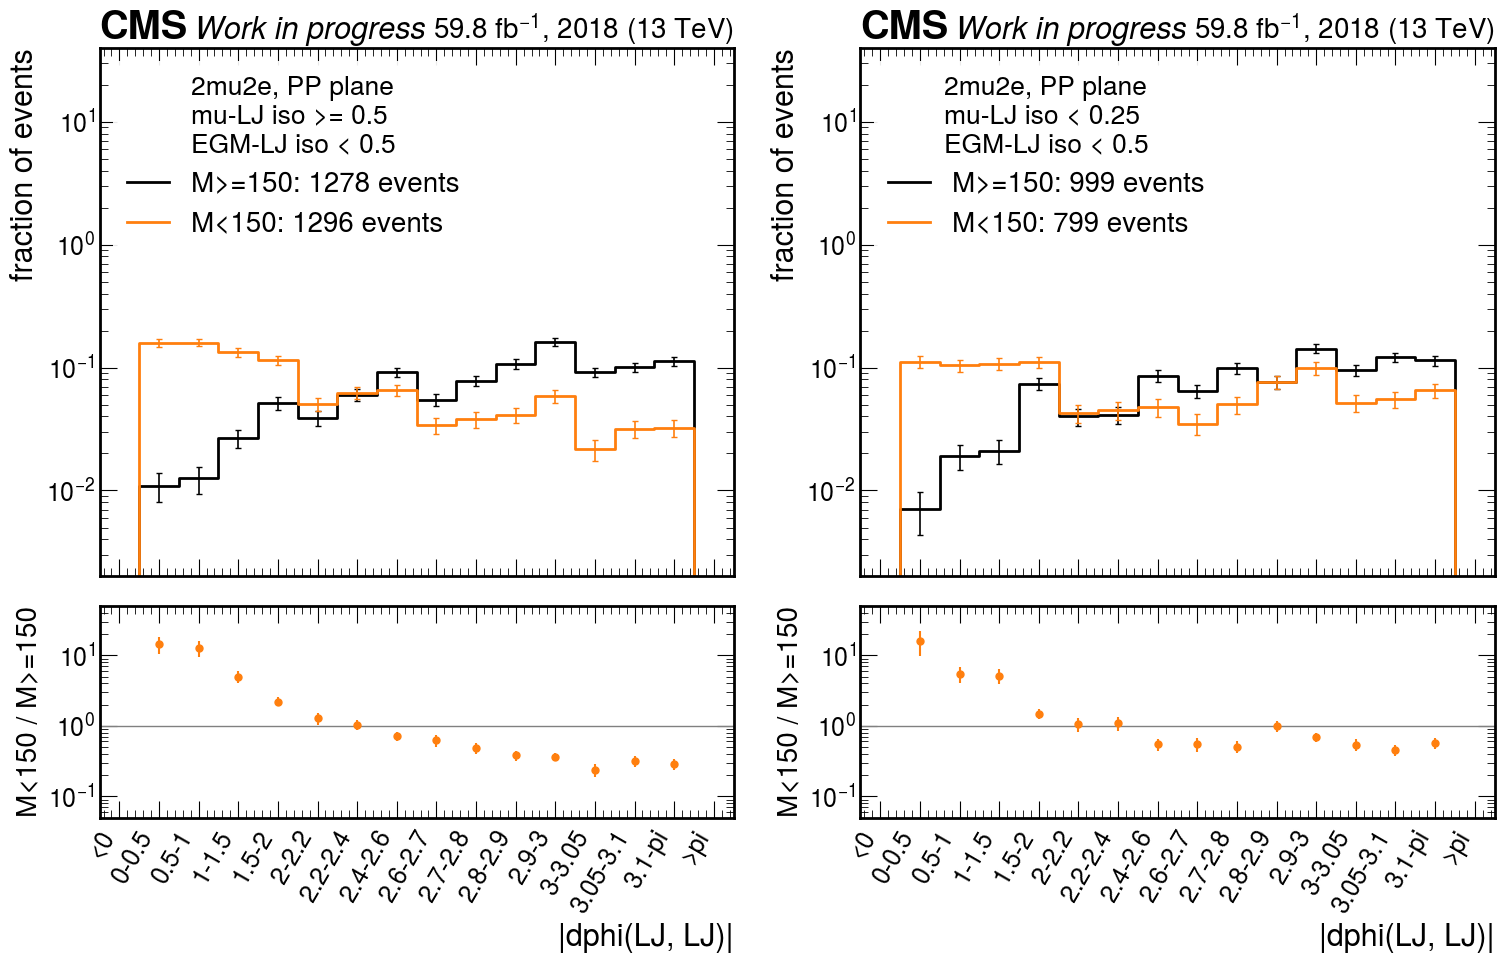

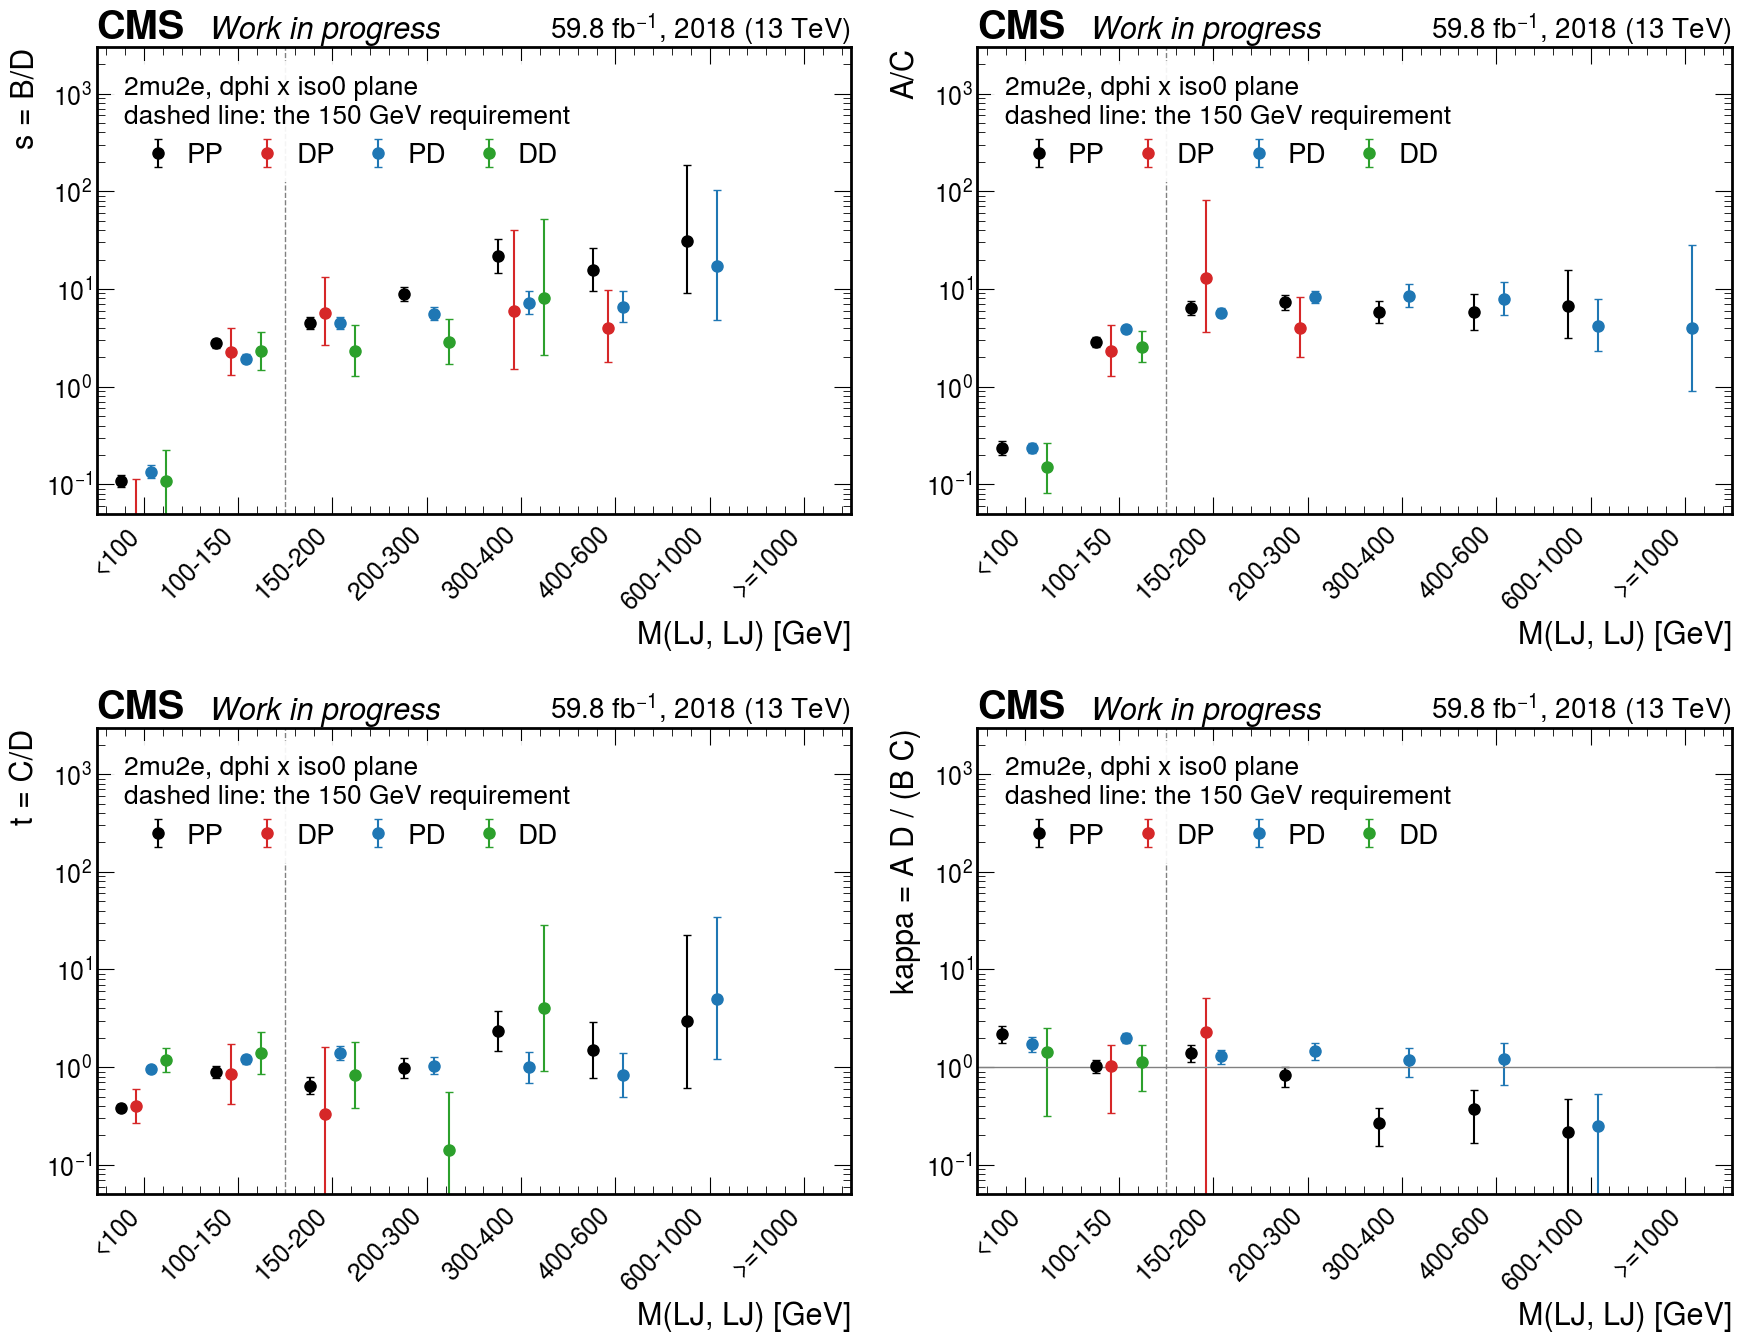

2mu2e, analysis plane, PP (mu-LJ prompt, EGM-LJ prompt), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,55,65,232,605,0.11 -0.01 +0.02,0.24 -0.04 +0.04,0.38 -0.03 +0.03,0.85 -0.15 +0.19,24.9 ± 3.6,2.21 ± 0.44
1,100-150,328,353,114,127,2.78 -0.29 +0.32,2.88 -0.31 +0.35,0.90 -0.12 +0.13,0.93 -0.07 +0.08,316.9 ± 44.2,1.04 ± 0.16
2,150-200,292,320,46,71,4.51 -0.59 +0.68,6.35 -0.99 +1.19,0.65 -0.12 +0.15,0.91 -0.07 +0.08,207.3 ± 40.9,1.41 ± 0.29
3,200-300,306,381,42,43,8.86 -1.41 +1.69,7.29 -1.18 +1.43,0.98 -0.21 +0.26,0.80 -0.06 +0.07,372.1 ± 83.0,0.82 ± 0.19
4,300-400,121,194,21,9,21.56 -6.91 +10.80,5.76 -1.32 +1.76,2.33 -0.87 +1.44,0.62 -0.07 +0.08,452.7 ± 183.3,0.27 ± 0.11
5,400-600,52,93,9,6,15.50 -5.98 +10.65,5.78 -1.96 +3.13,1.50 -0.72 +1.43,0.56 -0.10 +0.12,139.5 ± 74.9,0.37 ± 0.21
6,600-1000,20,31,3,1,31.00 -21.95 +153.74,6.67 -3.52 +8.91,3.00 -2.38 +19.66,0.65 -0.18 +0.25,93.0 ± 108.7,0.22 ± 0.26
7,>=1000,6,2,0,0,n/a,n/a,n/a,3.00 -1.96 +7.07,n/a,n/a


2mu2e, analysis plane, PD (mu-LJ prompt, EGM-LJ displaced), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,102,61,436,452,0.13 -0.02 +0.02,0.23 -0.03 +0.03,0.96 -0.06 +0.07,1.67 -0.27 +0.32,58.8 ± 8.5,1.73 ± 0.30
1,100-150,776,321,200,166,1.93 -0.18 +0.20,3.88 -0.31 +0.33,1.20 -0.13 +0.14,2.42 -0.16 +0.17,386.7 ± 46.0,2.01 ± 0.25
2,150-200,574,321,100,72,4.46 -0.58 +0.67,5.74 -0.62 +0.70,1.39 -0.21 +0.25,1.79 -0.12 +0.13,445.8 ± 73.3,1.29 ± 0.22
3,200-300,494,325,60,58,5.60 -0.79 +0.93,8.23 -1.11 +1.30,1.03 -0.19 +0.23,1.52 -0.11 +0.12,336.2 ± 64.7,1.47 ± 0.29
4,300-400,171,144,20,20,7.20 -1.67 +2.22,8.55 -1.96 +2.61,1.00 -0.31 +0.44,1.19 -0.13 +0.15,144.0 ± 47.1,1.19 ± 0.40
5,400-600,79,79,10,12,6.58 -1.95 +2.87,7.90 -2.51 +3.86,0.83 -0.34 +0.56,1.00 -0.16 +0.19,65.8 ± 29.1,1.20 ± 0.55
6,600-1000,21,17,5,1,17.00 -12.19 +86.70,4.20 -1.88 +3.74,5.00 -3.80 +29.24,1.24 -0.39 +0.57,85.0 ± 95.4,0.25 ± 0.28
7,>=1000,4,0,1,0,n/a,4.00 -3.09 +24.45,n/a,n/a,n/a,n/a


2mu2e, analysis plane, DD (mu-LJ displaced, EGM-LJ displaced), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,5,3,33,28,0.11 -0.06 +0.12,0.15 -0.07 +0.12,1.18 -0.30 +0.40,1.67 -1.03 +2.92,3.5 ± 2.2,1.41 ± 1.09
1,100-150,36,23,14,10,2.30 -0.82 +1.32,2.57 -0.78 +1.14,1.40 -0.55 +0.91,1.57 -0.41 +0.55,32.2 ± 14.9,1.12 ± 0.55
2,150-200,blind,14,5,6,2.33 -1.04 +1.98,n/a,0.83 -0.45 +0.98,n/a,11.7 ± 7.7,n/a
3,200-300,blind,20,1,7,2.86 -1.16 +2.06,n/a,0.14 -0.12 +0.41,n/a,2.9 ± 3.1,n/a
4,300-400,blind,8,4,1,8.00 -5.90 +43.60,n/a,4.00 -3.09 +24.45,n/a,32.0 ± 37.5,n/a
5,400-600,blind,5,1,0,n/a,n/a,n/a,n/a,n/a,n/a
6,600-1000,blind,3,0,0,n/a,n/a,n/a,n/a,n/a,n/a
7,>=1000,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a


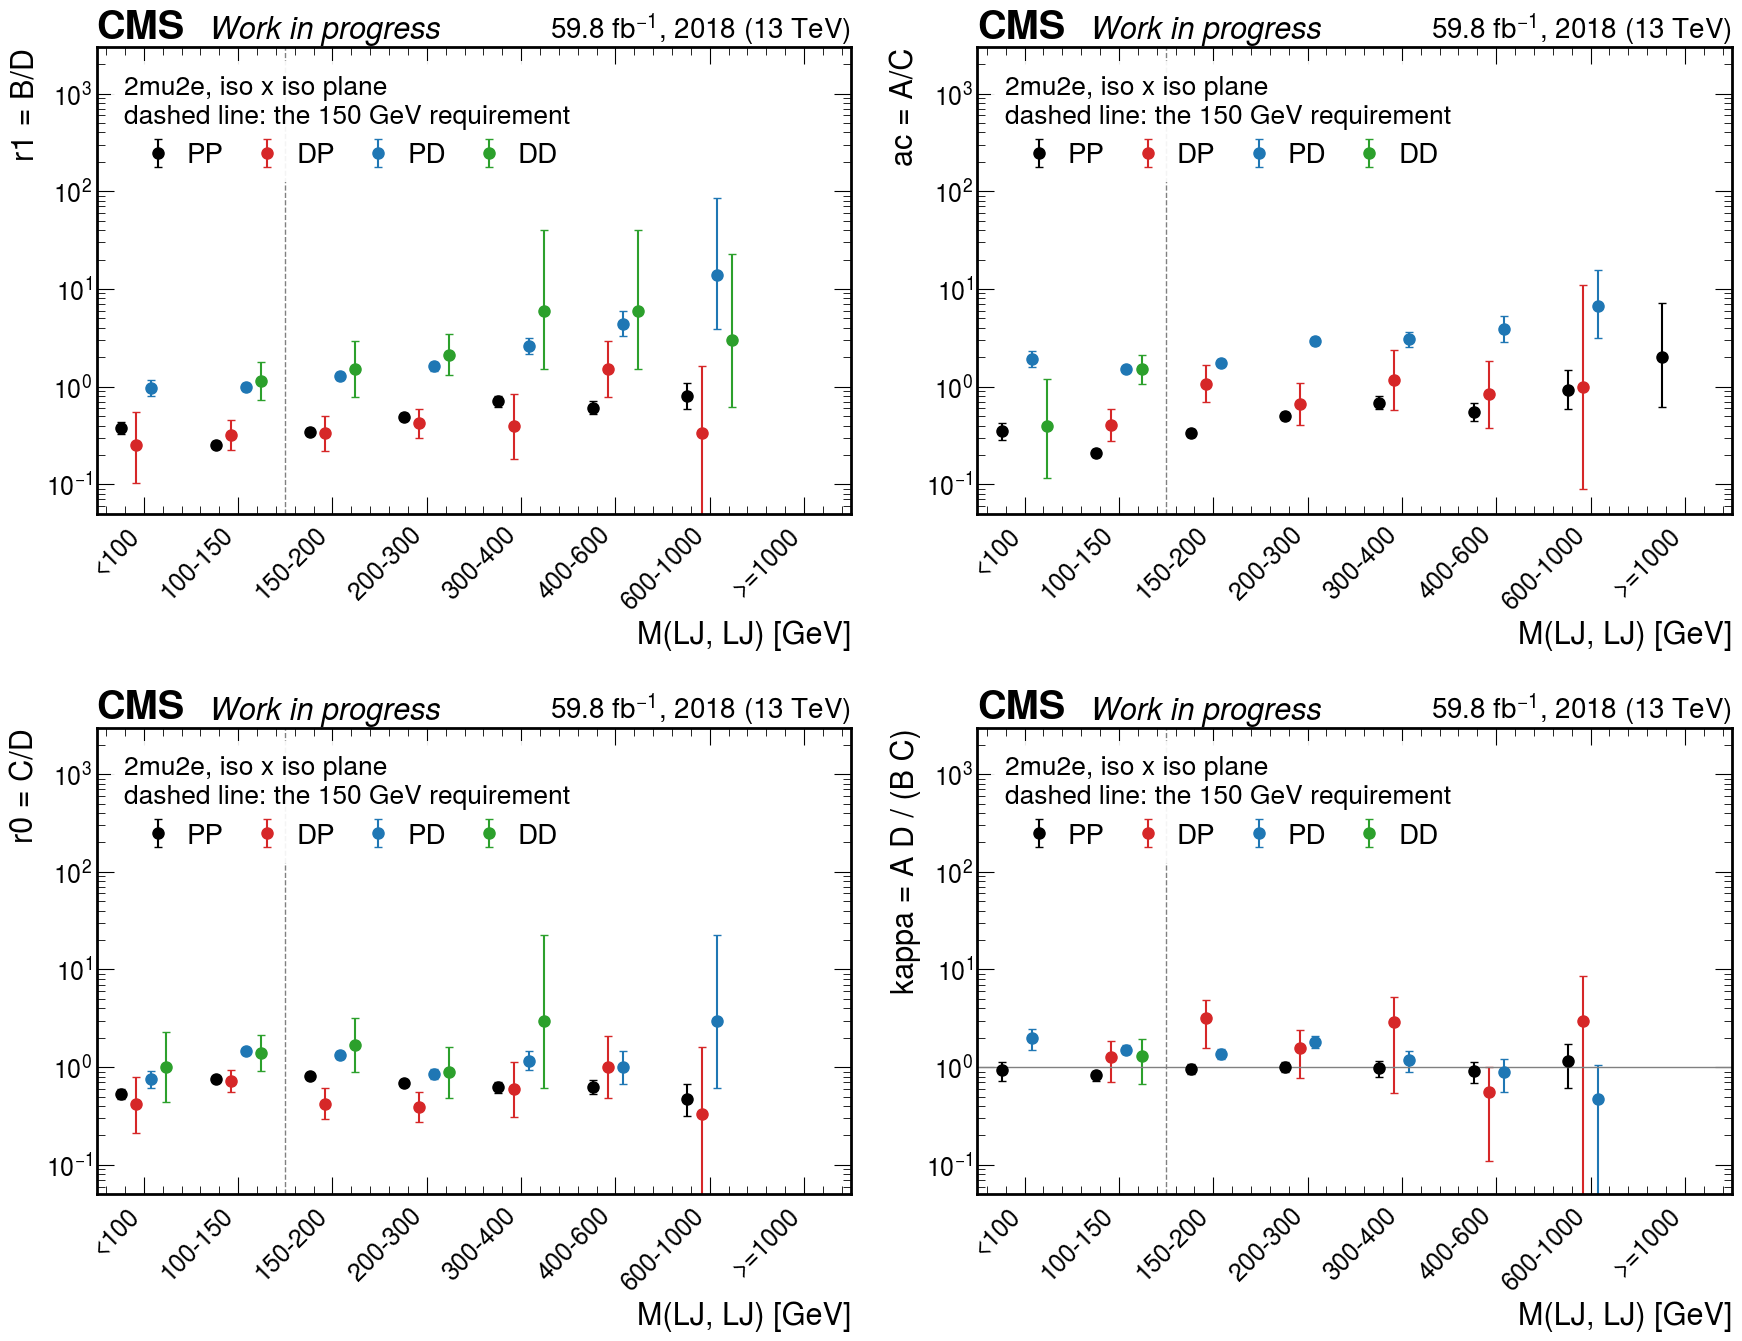

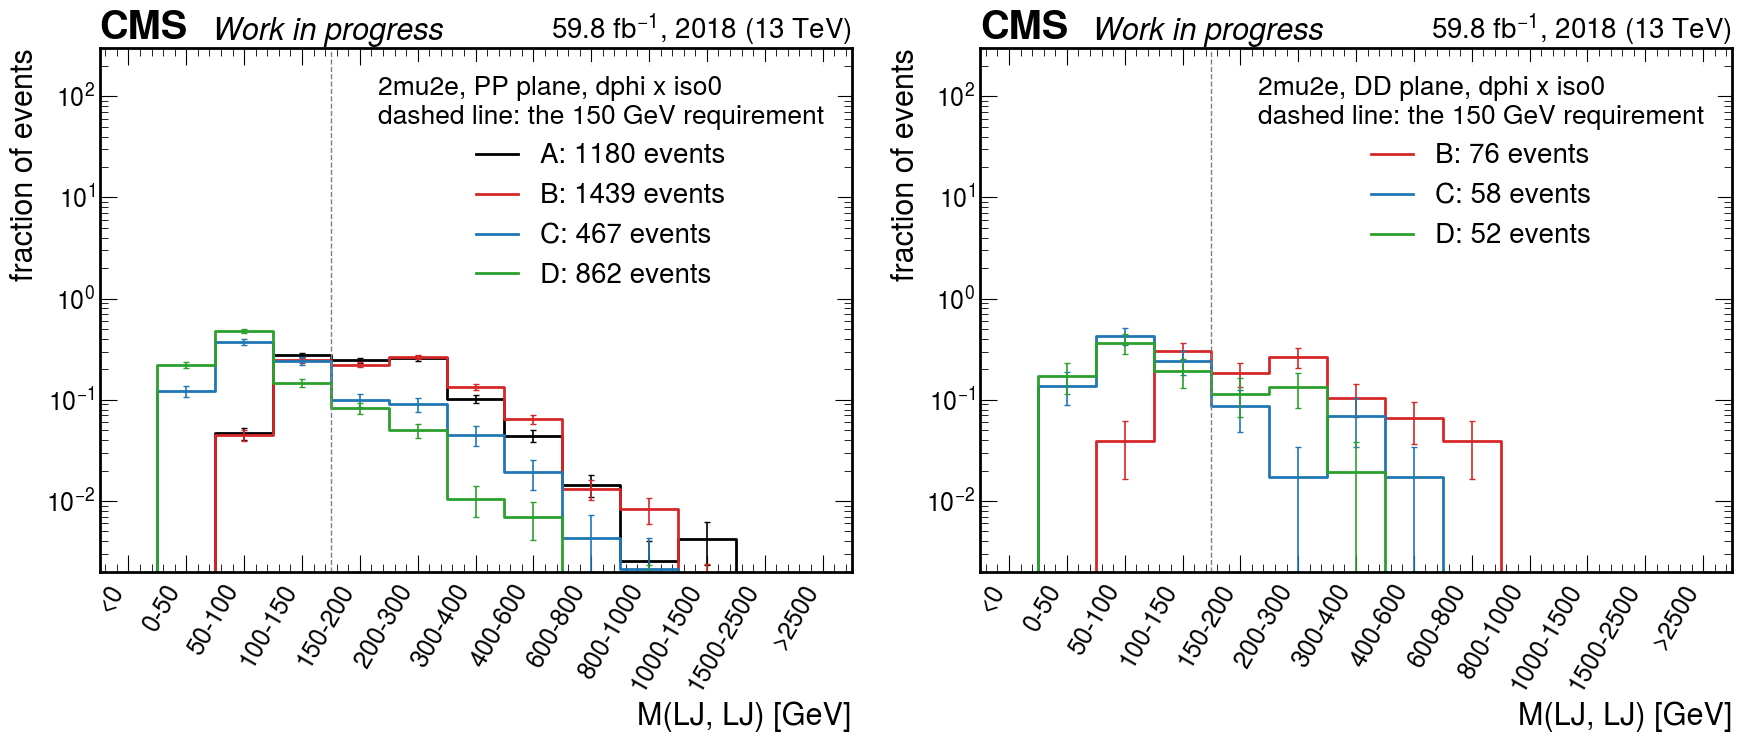

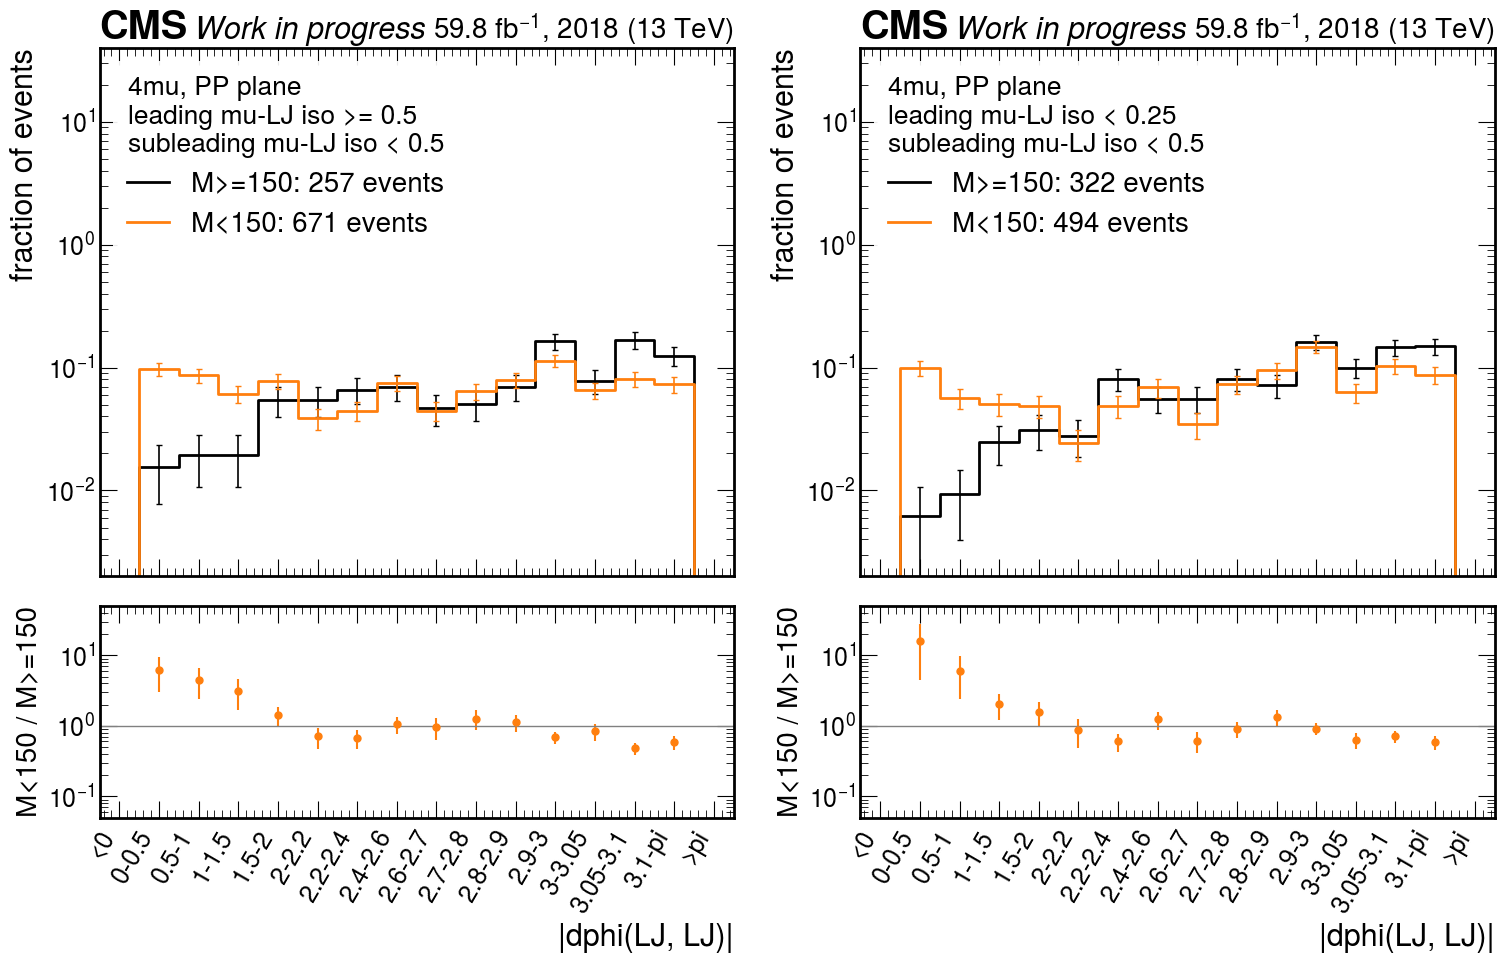

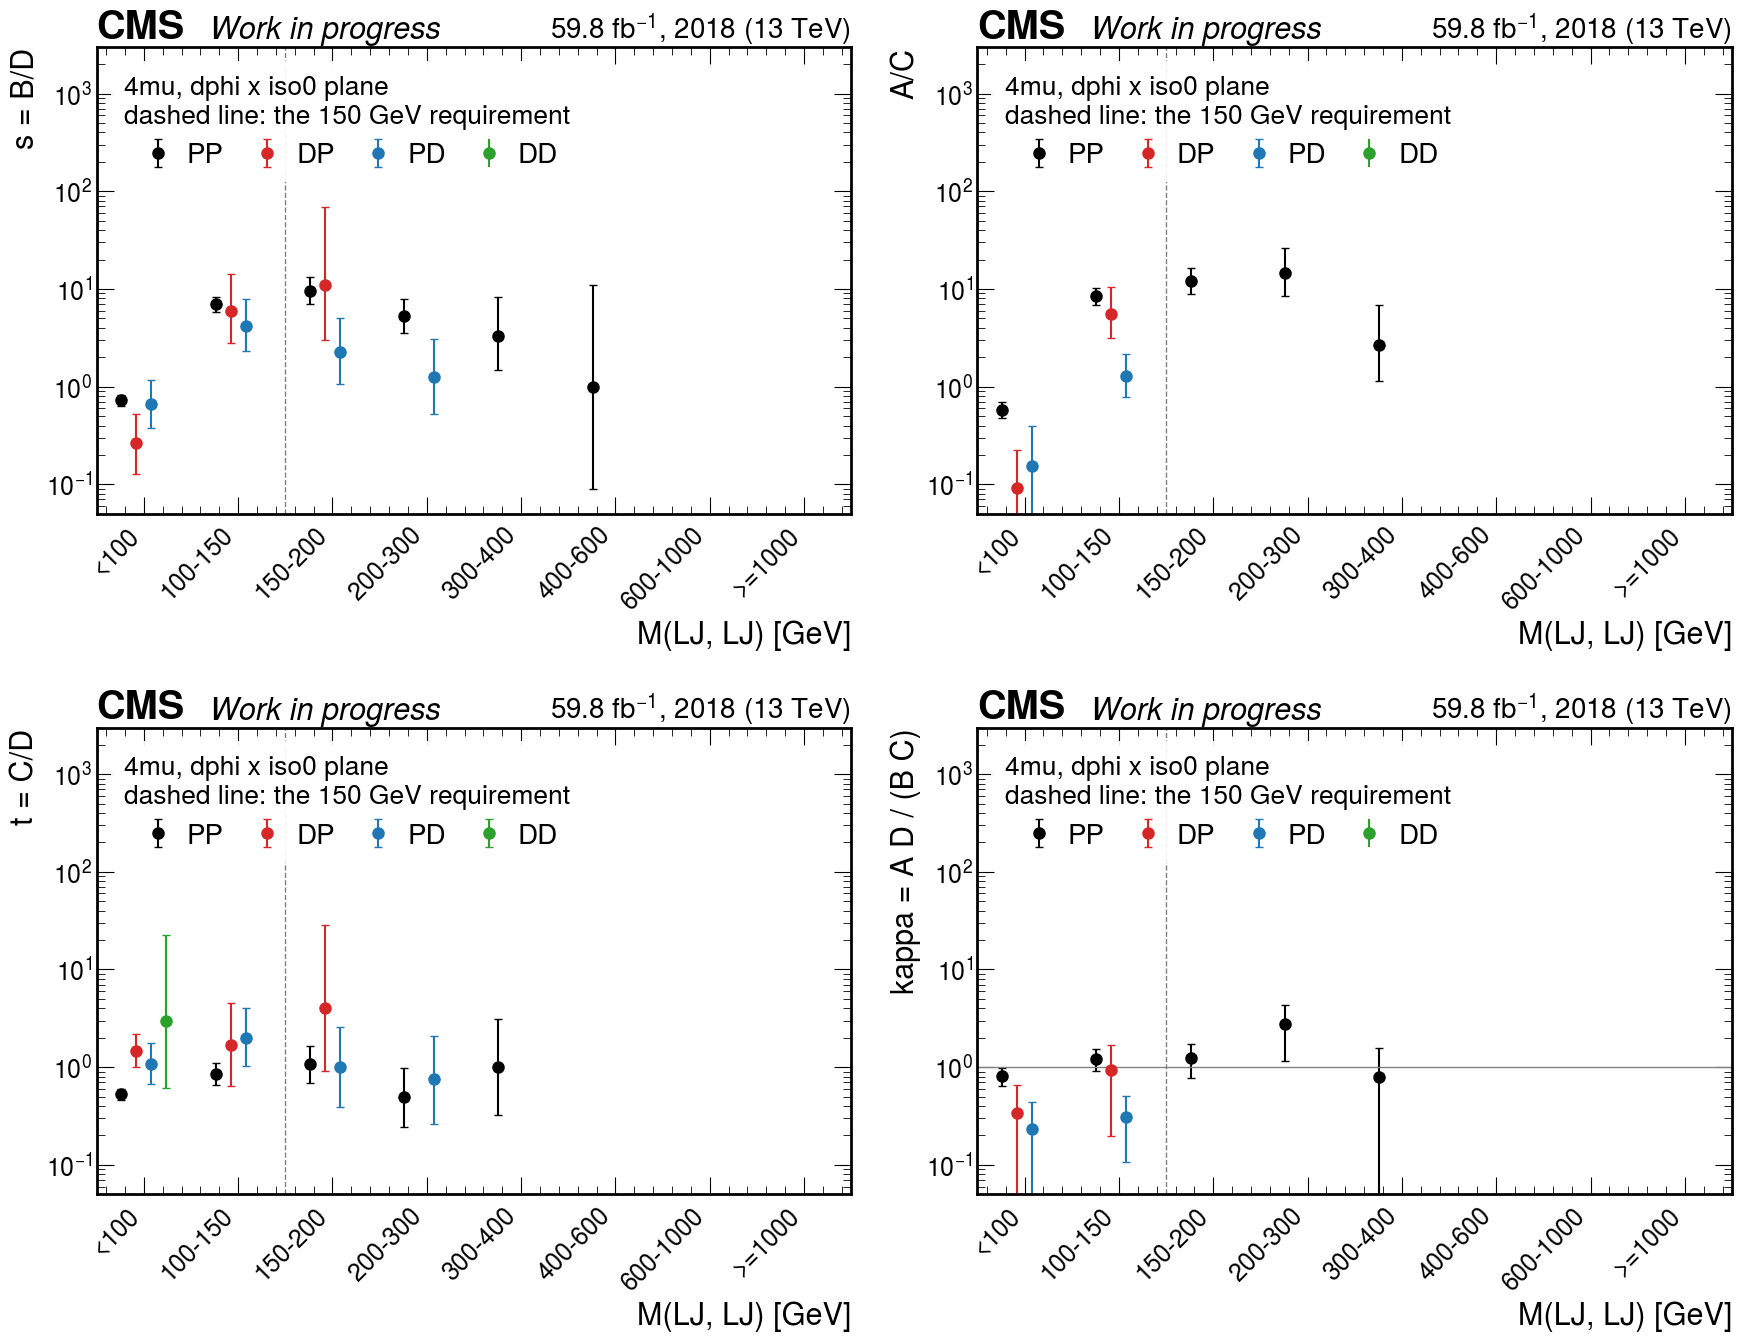

4mu, analysis plane, PP (leading mu-LJ prompt, subleading mu-LJ prompt), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,54,128,93,177,0.72 -0.08 +0.09,0.58 -0.10 +0.12,0.53 -0.07 +0.08,0.42 -0.07 +0.08,67.3 ± 10.5,0.80 ± 0.17
1,100-150,278,271,33,39,6.95 -1.17 +1.43,8.42 -1.52 +1.89,0.85 -0.20 +0.26,1.03 -0.09 +0.10,229.3 ± 56.0,1.21 ± 0.30
2,150-200,180,134,15,14,9.57 -2.58 +3.66,12.00 -3.10 +4.33,1.07 -0.38 +0.59,1.34 -0.15 +0.17,143.6 ± 54.8,1.25 ± 0.49
3,200-300,73,53,5,10,5.30 -1.73 +2.68,14.60 -6.09 +11.65,0.50 -0.25 +0.48,1.38 -0.25 +0.30,26.5 ± 15.0,2.75 ± 1.59
4,300-400,8,10,3,3,3.33 -1.87 +4.93,2.67 -1.53 +4.13,1.00 -0.68 +2.11,0.80 -0.35 +0.63,10.0 ± 8.8,0.80 ± 0.76
5,400-600,1,1,0,1,1.00 -0.91 +10.08,n/a,0.00 -0.00 +5.30,1.00 -0.91 +10.08,n/a,n/a
6,600-1000,2,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
7,>=1000,0,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a


4mu, analysis plane, PD (leading mu-LJ prompt, subleading mu-LJ displaced), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,2,8,13,12,0.67 -0.29 +0.49,0.15 -0.10 +0.24,1.08 -0.41 +0.67,0.25 -0.17 +0.43,8.7 ± 4.6,0.23 ± 0.20
1,100-150,13,21,10,5,4.20 -1.88 +3.74,1.30 -0.51 +0.86,2.00 -0.98 +2.06,0.62 -0.21 +0.31,42.0 ± 24.8,0.31 ± 0.20
2,150-200,blind,9,4,4,2.25 -1.19 +2.74,n/a,1.00 -0.61 +1.58,n/a,9.0 ± 7.0,n/a
3,200-300,blind,5,3,4,1.25 -0.73 +1.81,n/a,0.75 -0.49 +1.34,n/a,3.8 ± 3.3,n/a
4,300-400,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
5,400-600,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
6,600-1000,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
7,>=1000,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a


4mu, analysis plane, DD (leading mu-LJ displaced, subleading mu-LJ displaced), by mass bin


,mass bin,A,B,C,D,s = B/D,A/C,t = C/D,A/B,B C / D,kappa
0,<100,0,0,3,1,0.00 -0.00 +5.30,0.00 -0.00 +0.85,3.00 -2.38 +19.66,n/a,n/a,n/a
1,100-150,2,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
2,150-200,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
3,200-300,blind,1,0,0,n/a,n/a,n/a,n/a,n/a,n/a
4,300-400,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
5,400-600,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
6,600-1000,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a
7,>=1000,blind,0,0,0,n/a,n/a,n/a,n/a,n/a,n/a


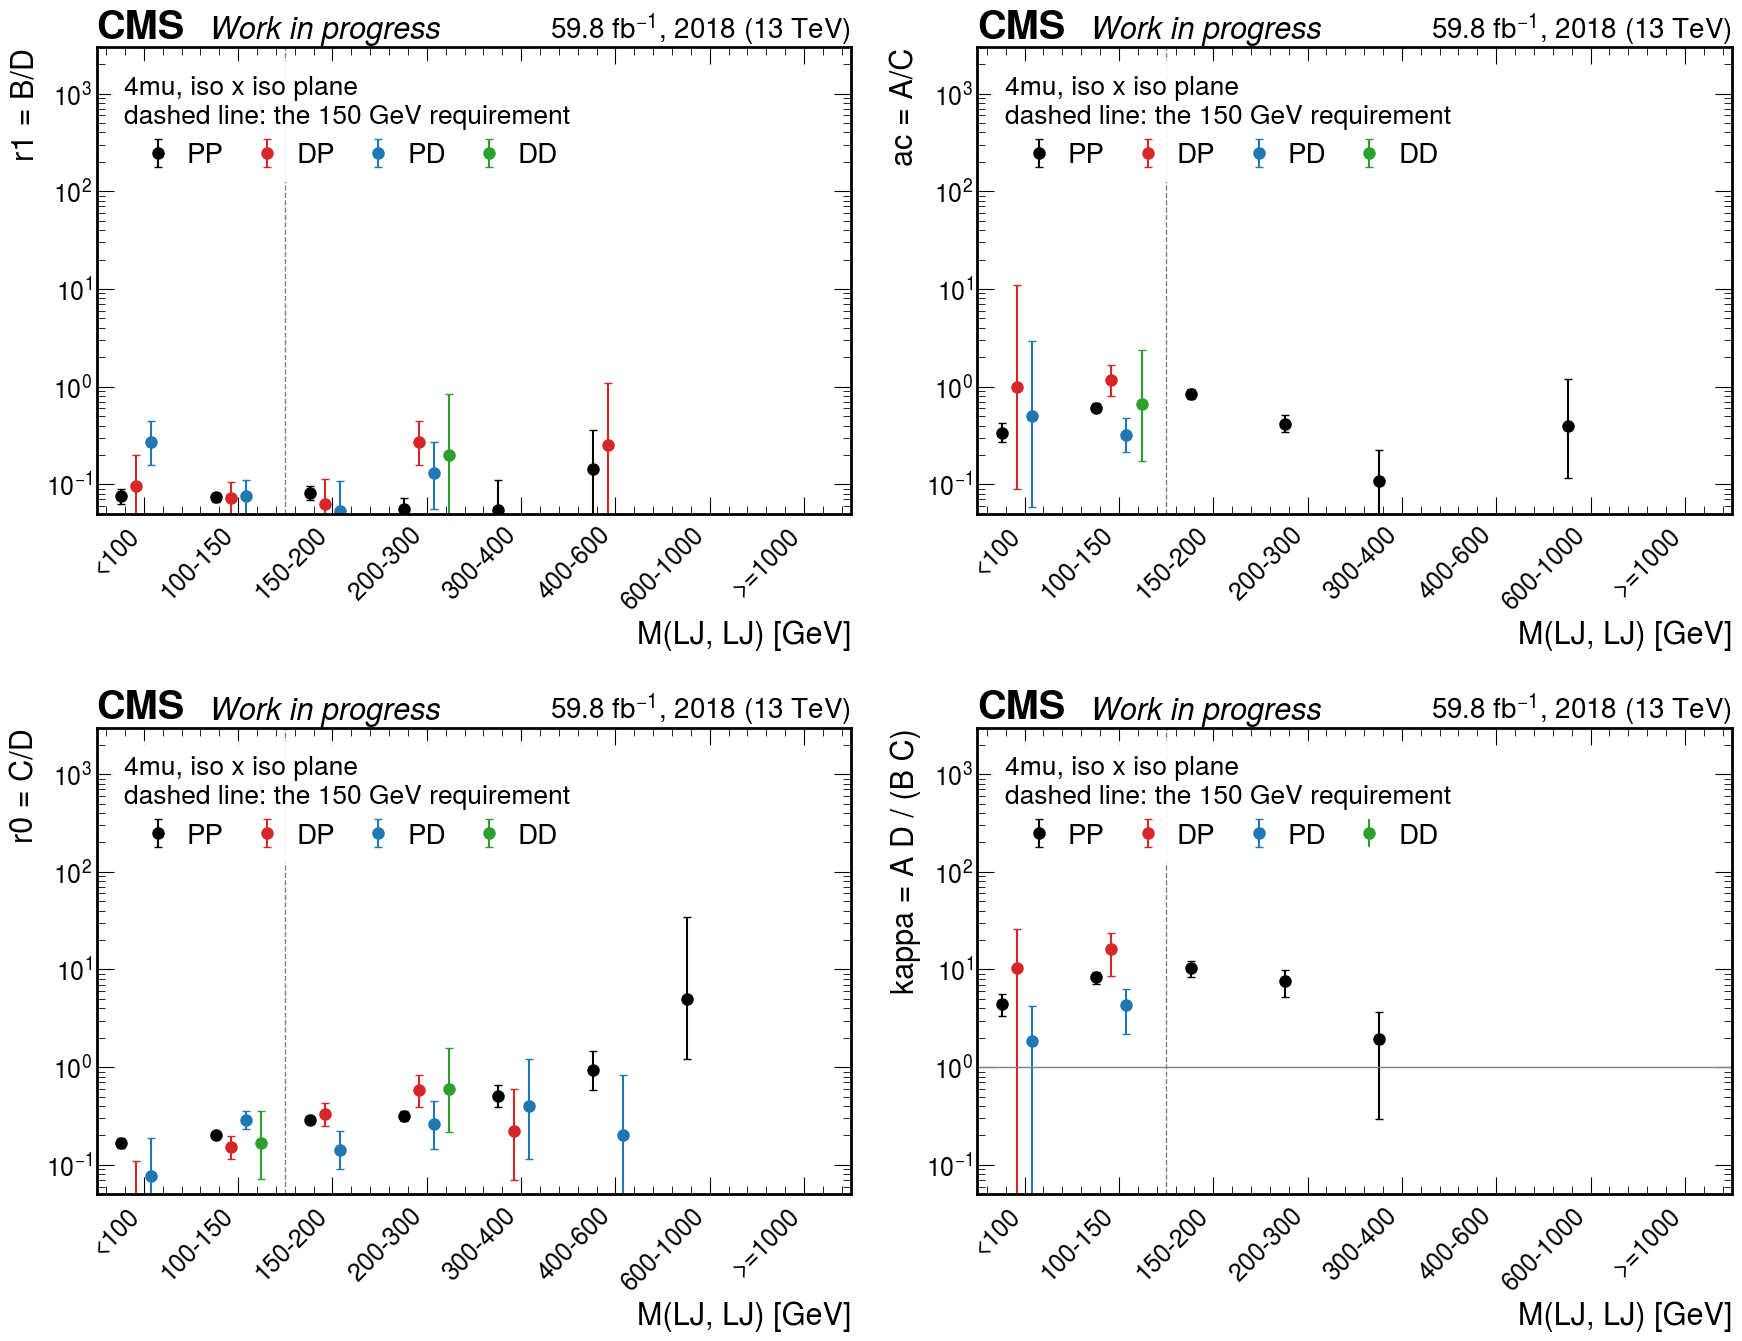

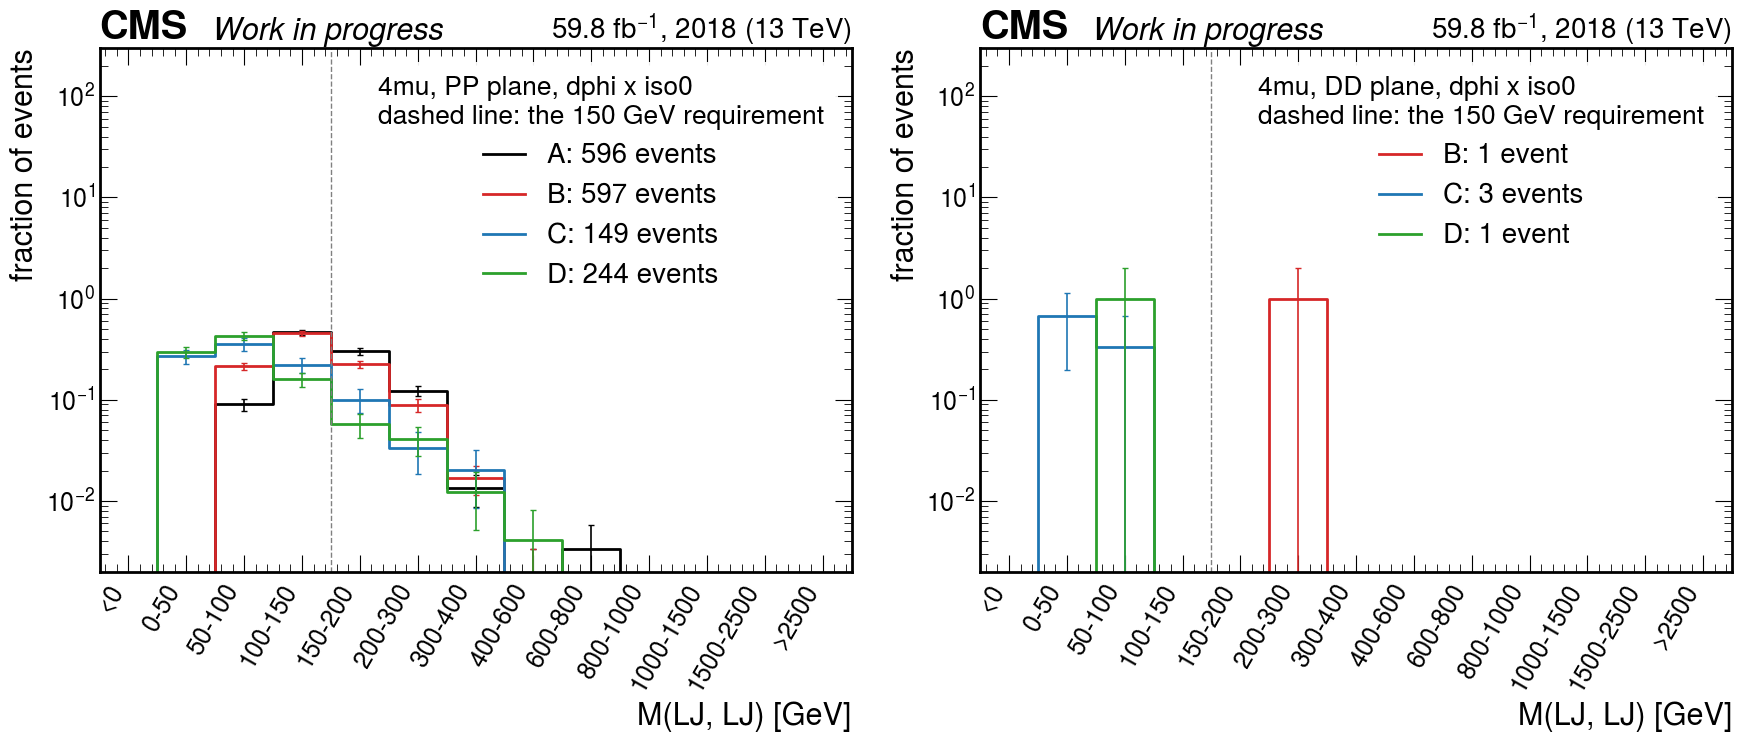

In [14]:
for t in tl.TOPOLOGIES:
    fig = tp.mass_window_dphi_figure(data[t], "PP")
    plt.show()
    fig = tp.mass_factor_figure(data[t], "dphi x iso0")
    plt.show()
    for plane in ("PP", "PD", "DD"):
        print(f"{t}, analysis plane, {plane} ({tl.plane_label(t, plane)}), by mass bin")
        display(tl.mass_scan(data[t], plane, "dphi x iso0"))
    fig = tp.mass_factor_figure(data[t], "iso x iso")
    plt.show()
    fig = tp.mass_shape_figure(data[t], "dphi x iso0")
    plt.show()

## 6. Verdict

**Short form.** Across the muon LJ's displacement, the one that turns the PD plane into the search
plane, every ratio of the analysis plane is consistent with transferring, but the displaced-muon
planes hold 5–14 events in the regions that set them, so "consistent" means 20–110% uncertainties.
Across the egamma LJ's displacement, where both ends have hundreds of events per region, three
of the four ratios change: s = B/D by 0.69 ± 0.09, t = C/D by 1.29 ± 0.23 and A/B by 1.94 ± 0.13,
while A/C stays (1.04 ± 0.14). A factor measured with prompt LJs therefore does not in general
describe displaced ones, and the recipes for the search region differ by a factor two depending
on which assumption replaces κ = 1. The companion plane locates the egamma side of this in the
egamma LJ's isolation response, in particular in the photon-only LJs, which have no prompt
counterpart. The mass axis shows that κ itself depends on the LJ-pair mass inside the
M ≥ 150 GeV window. 4μ has statistics only in its PP plane; its few finite ratios point the same
way as 2μ2e for s and the opposite way for the companion-plane C/D.

### 6.1 The analysis plane (2μ2e, M ≥ 150 GeV)

*Muon LJ prompt → displaced* (PP → DP with the egamma LJ prompt, PD → DD with it displaced;
section 1b):

- s = B/D: 0.98 (−0.38/+0.63) and 0.66 (−0.20/+0.28); the fail-slice $|\Delta\phi|$ shapes agree
  (χ²/ndf 8.6/13 and 12.8/13).
- t = C/D: 0.77 (−0.42/+0.85) and 0.65 (−0.26/+0.41).
- A/C: 1.34 (−0.59/+1.11), PP → DP only (the PD → DD end is the search region). A/B: 1.04
  (−0.22/+0.27).
- Closure of the DP plane (A = 44 observed, section 1c): 1.12 ± 0.54 from C × s(PP), 1.34 ± 0.65
  from C × A/C(PP), 0.88 ± 0.22 from B × t(PP), 1.04 ± 0.22 from B × A/B(PP), 1.14 ± 0.71 in-plane.

All consistent with 1; the PD → DD values sit below it by 1.2σ (s) and 0.9σ (t). With C = 5 and
D = 7 in DP and 11 and 14 in DD this is the precision the data allow, and it does not distinguish
a transferring factor from one that changes by 30–40%.

*Egamma LJ prompt → displaced* (PP → PD, every region above 100 events):

- s = B/D: 0.69 ± 0.09. Events whose muon LJ fails isolation are less often back-to-back once the
  egamma LJ is displaced.
- t = C/D: 1.29 ± 0.23. A/B: 1.94 ± 0.13.
- A/C: 1.04 ± 0.14. The $|\Delta\phi|$ pass/fail ratio among events with an isolated muon LJ is
  the one quantity that stays.
- Hence κ_PP = 0.84 ± 0.11 and κ_PD = 1.26 ± 0.14 (κ = (A/C)/(B/D)), 2.3σ apart; the PP closure of
  the status report (0.76 ± 0.10) is the same number with its boundaries. The closure of the PD plane from PP factors reads the same
  way: 0.87 (−0.11/+0.10) from C × s(PP), 1.04 (−0.14/+0.13) from C × A/C(PP), 1.63 (−0.24/+0.22)
  from B × t(PP), 1.94 ± 0.13 from B × A/B(PP).

*What this leaves for the search region* (A of the DD plane; B = 50, C = 11, D = 14; section 1c):

- in-plane B C/D (κ = 1): 39 ± 17; B C/D × κ_PP: 33 ± 15; B C/D × κ_PD: 50 ± 22;
- C × A/C from PD or PP (A/C transfers): 75 ± 24 and 72 ± 23; B × A/B from PP: 39 ± 6, from PD:
  76 ± 11;
- C × s from PD: 60 ± 19, from PP: 86 ± 28. These are B C/D times the ratio of the two s values
  and still assume κ_DD = 1.

The 33–39 family assumes κ_DD = 1 or κ_DD = κ_PP; the 72–76 family assumes the search region's
A/C is the PD (or PP) value. Since C × (A/C)_X = (B C/D)_DD × κ_X × s_X/s_DD for any source plane
X, the second family is the in-plane estimate times κ_PD × s_PD/s_DD = 1.26 × 1.52 = 1.9 (from PD)
or κ_PP × s_PP/s_DD = 0.84 × 2.20 = 1.8 (from PP). The factor two between the families is the
change of s from PP to DD, 1.45 across the egamma displacement times 1.52 across the muon
displacement; the first of these is measured to ±13%, the second is the 1.2σ effect above. The
question it poses is whether the s of the DD fail slice, 3.6 (−1.0/+1.5), is the $|\Delta\phi|$
pass/fail ratio of the search region's own population (then the in-plane estimate holds up to
κ_DD) or whether that ratio is the 5.4–7.9 of the isolated muon LJs in PD and PP. No open region
at M ≥ 150 GeV decides this, and the DP-sourced recipes (36–97) carry 50–90% errors. The one
place where the A/C transfer across the muon displacement can be
tested with the egamma LJ displaced is the DD plane at M < 150 GeV: C × A/C(PD) predicts 65 ± 10
for 41 observed (0.63 ± 0.14), the in-plane B C/D 32 ± 9 (1.27 ± 0.42). Low mass has different
kinematics (section 5), so this is not a measurement of the M ≥ 150 GeV case; it is a
counter-example to "A/C of the isolated muon LJ does not depend on the other LJ's displacement"
as a general statement.

### 6.2 The companion plane

- r1 = B/D, the egamma LJ's isolation ratio among muon-LJ failures, is consistent with
  transferring across the muon LJ's displacement where the egamma LJ is prompt, 0.95
  (−0.18/+0.22) PP → DP, and 1.2σ above it where the egamma LJ is displaced, 1.40 (−0.39/+0.54)
  PD → DD; the shapes are compatible in both (χ²/ndf 9.6/13 and 9.6/11). The scan against pixel
  hits (section 2c) shows no step at the displacement boundary: with the egamma LJ prompt, r1 is
  0.31–0.49 in the displaced-muon bins against 0.41–0.54 in the prompt ones; with it displaced,
  1.5–2.2 against 1.5–1.8.
- A/C, the same ratio among muon-LJ passes, does not: 1.99 (−0.45/+0.57) PP → DP. The DP plane's
  κ is 2.01 ± 0.59 and its isolated corner (38 events) is predicted at 19–20 by every PP factor.
  The scan puts the change in the two-pixel-hit bin (31/36 = 0.86 against 0.37–0.52 in the prompt
  bins), which holds 31 of the 38 events; the zero- and one-hit bins hold 5 and 2.
- r0 = C/D and A/B, the muon LJ's ratios across the egamma LJ's displacement: 1.55 ± 0.13 and
  2.25 ± 0.18, with incompatible shapes (χ²/ndf 55.8/13). The scan against lost hits says where:
  with the muon LJ prompt, C/D is 0.72 for prompt egamma LJs (1056/1464), 0.71 for displaced
  electron-type ones (84/119, lost hits 1–9) and 1.28 for the photon-only LJs (399/312); A/B is
  0.69, 1.07–1.19 and 1.62 in the same three classes. The photon-only class, which the lost-hits
  sentinel puts in the displaced category, has no prompt counterpart and drives the integrated
  change; the electron-type displaced LJs transfer C/D but not A/B.
- Against mass (section 5), the PP plane factorises in every bin (κ 0.9–1.2 above 150 GeV) while
  the PD plane does not in the 150–300 GeV bins that hold most of its events (1.37 ± 0.17,
  1.81 ± 0.25) and is consistent with 1 above 300 GeV within 30% errors: the PD non-closure is a
  property of the displaced egamma LJ, not of the mass mixture.

The companion-plane recipes for the hidden isolated DD corner span 20–106 for the same reason
as in the analysis plane.

### 6.3 The mass axis

- The 150 GeV requirement changes what the ABCD axes sort on. In the validation plane s = B/D is
  0.57 ± 0.04 below 150 GeV and 7.9 ± 0.8 above, A/C 1.11 ± 0.09 and 6.6 ± 0.7: low-mass pairs
  are mostly not back-to-back, high-mass pairs mostly are. Nothing measured below 150 GeV
  describes the window above it.
- Inside M ≥ 150 GeV the factors keep moving. In PP, s rises from 4.5 (150–200 GeV) through 8.9,
  21.6 and 15.5 to 31 (600–1000 GeV) while A/C stays at 5.8–7.3, so κ_PP falls from 1.41 ± 0.29
  to 0.82 ± 0.19, 0.27 ± 0.11, 0.37 ± 0.21 and 0.22 ± 0.26. The integrated κ_PP = 0.84 averages
  over this: a validation-plane closure within 5–25% is a statement about the mass mixture of
  PP, not about the plane. In PD, s rises more slowly (4.5, 5.6, 7.2, 6.6, 17) and κ_PD stays at
  1.2–1.5 up to 600 GeV. PP and PD agree at 150–200 GeV (s 4.51 vs 4.46) and separate above (8.9
  vs 5.6, 21.6 vs 7.2, 15.5 vs 6.6): the integrated s change of 0.69 is a high-mass effect, and
  the mass spectra of the regions differ (the fail/fail region D is the softest).
- Bin-by-bin factors: in the DD plane at M ≥ 150 GeV the mass bins hold B/C/D = 14/5/6, 20/1/7,
  8/4/1, 5/1/0 and 3/0/0 events (150–200, 200–300, 300–400, 400–600, 600–1000 GeV). A per-bin
  factor cannot be measured in the search plane,
  and an imported one cannot be validated there; the PP and PD per-bin factors differ from each
  other above 200 GeV, so the choice of source plane would be the dominant systematic of such a
  scheme with 2018 data.

### 6.4 Signal and simulation

- The fail slices that set s and t hold at most 0.2% of the signal's search-region yield (B and D
  of every plane at M ≥ 150 GeV, all seven points); the C regions hold 0.5–1.6% in the analysis
  plane's DD plane and 3–8% in the companion plane's. The isolated corners of DP and PD, open in
  2μ2e, hold 7–17% (DP) and 18–42% (PD) of it, with signal over data at most 0.26 and 0.02 at the
  stored cross sections. A recipe of the form C × factor absorbs the C-region signal into the
  background estimate: 3–13% of the signal yield with the analysis-plane C (its share times s of
  5–8), 5–13% with the companion-plane C, at any cross section.
- The simulation's DD plane holds between zero and 150 weighted events per region, with 50–100%
  uncertainties; its validation-plane κ is 3.2 ± 2.3 (analysis plane) and 1.6 ± 0.7 (companion
  plane). It decides nothing.

### 6.5 4μ

The PP plane is the only one with statistics (264/198/23/28 at M ≥ 150 GeV, κ = 1.62 ± 0.48); the
DP and PD fail slices hold 24/4/1 and 14/7/8 events, the DD plane 1/0/0, so every ratio that
ends in DD is undefined and the PP → DP ratios rest on D = 1. The ratios with both ends
populated are PP → PD: s = 0.25 (−0.12/+0.19) and t = 1.07 (−0.65/+1.01) in the analysis plane,
with fail-slice $|\Delta\phi|$ shapes that differ (χ²/ndf 31.0/13 on 23 events), and
C/D = 0.59 (−0.16/+0.21) in the companion plane. The s change points the same way as in 2μ2e (s
drops when the second LJ is displaced); the companion-plane C/D moves the opposite way to 2μ2e's
1.55 ± 0.13. The isolated corners of DP and PD are hidden here because they hold up to half of
the search-region signal (section 4) against a predicted background of 20 and 12 events
(B × t(PP), section 1c). Beyond this the 2018 data say nothing about 4μ.

### 6.6 What this does and does not establish

Established:

1. The ratios among failures (B/D, C/D) are open in the search plane and the data test them
   directly; the ratios among passes (A/C, A/B) are not. Across the muon LJ's displacement all
   four are consistent with transferring at 20–110% precision; across the egamma LJ's
   displacement s, t and A/B change (0.69 ± 0.09, 1.29 ± 0.23, 1.94 ± 0.13) and A/C does not
   (1.04 ± 0.14).
2. A search-region prediction built from a prompt-plane ratio among failures is the in-plane
   B C/D times the ratio of the two factors and inherits the κ_DD = 1 assumption; one built from
   a ratio among passes assumes that ratio is the same in the search region. The sixteen recipes
   span 33–97 for a region whose in-plane estimate is 39 ± 17.
3. κ of the analysis plane depends on the LJ-pair mass inside the M ≥ 150 GeV window (PP:
   1.4 → 0.2) and on the egamma LJ's displacement (0.84 → 1.26); κ_PP = 1 within 5–25% is a
   property of the integrated PP sample.
4. The egamma-LJ side of the non-transfer is traceable to the photon-only LJs (lost-hits
   sentinel), which have no prompt analogue; the electron-type displaced LJs transfer C/D
   (0.71 vs 0.72) but not A/B (1.1 vs 0.69).

Not established:

- Whether κ_DD is closer to κ_PP (0.84), κ_PD (1.26) or 1. No open region at M ≥ 150 GeV
  constrains it; the low-mass DD plane gives 1.27 ± 0.42 in-plane and rejects the A/C transfer
  from PD (0.63 ± 0.14), with the kinematic caveat of section 5.
- Anything about the muon-LJ side of the DD plane beyond the 20–110% level: the displaced-muon
  fail slices need several times the 2018 statistics.
- Anything in 4μ.

For the group:

- A systematic on the DD estimate should cover at least the PP → PD variation of the factor used
  (30% on s, a factor two on A/B) and the κ spread 0.84–1.26; separating the egamma-LJ classes
  would address the egamma part of that variation, not the muon part.
- Separate the photon-only egamma LJs from the electron-type displaced ones in the ABCD, or at
  least show the estimate per class, and check the signal share per class at the same time.
- The mass dependence of κ inside the window needs either a per-bin treatment with an imported
  factor (and the PP–PD difference as its systematic) or a demonstration that the search region's
  mass mixture matches the plane the factor comes from.
- The regions opened here (the DD fail slices at M ≥ 150 GeV, the low-mass DD corner, the 2μ2e DP
  and PD isolated corners) should be agreed with the group before any number from them
  circulates.

In [15]:
summary = pd.concat([fn(data[t], mass) for t in tl.TOPOLOGIES for mass in ("M>=150", "M<150")
                     for fn in (tl.dphi_transfer_numbers, tl.transfer_numbers)], ignore_index=True)
summary.to_csv("transfer_summary.csv", index=False, float_format="%.4f")
summary

,topology,plane kind,mass,factor,prompt_plane,displaced_plane,prompt_value,prompt_minus,prompt_plus,displaced_value,displaced_minus,displaced_plus,ratio,ratio_minus,ratio_plus
0,2mu2e,dphi x iso0,M>=150,r1,PP,DP,7.853846,0.727796,0.804905,7.714286,2.869253,4.906608,0.982230,0.378946,0.631335
1,2mu2e,dphi x iso0,M>=150,r1,PD,DD,5.435583,0.461439,0.505544,3.571429,1.035785,1.501005,0.657046,0.200115,0.281721
2,2mu2e,dphi x iso0,M>=150,r1,PP,PD,7.853846,0.727796,0.804905,5.435583,0.461439,0.505544,0.692092,0.092103,0.090866
3,2mu2e,dphi x iso0,M>=150,r1,DP,DD,7.714286,2.869253,4.906608,3.571429,1.035785,1.501005,0.462963,0.323631,0.259827
4,2mu2e,dphi x iso0,M>=150,ac,PP,DP,6.586777,0.639276,0.710554,8.800000,3.745948,7.241685,1.336010,0.586685,1.107048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,4mu,iso x iso,M<150,ac,PD,DD,0.333333,0.108126,0.155140,0.666667,0.494815,1.704538,2.000000,1.752153,5.154604
92,4mu,iso x iso,M<150,r0,PP,PD,0.192169,0.010857,0.011494,0.248276,0.045860,0.055630,1.291966,0.250843,0.298543
93,4mu,iso x iso,M<150,r0,DP,DD,0.128205,0.030102,0.038422,0.150000,0.085818,0.167958,1.170000,0.755660,1.338565
94,4mu,iso x iso,M<150,ab,PP,PD,1.402778,0.152267,0.170984,0.750000,0.274081,0.426825,0.534653,0.205966,0.309756
